# Index

- [Libraries](#Libraries)
- [Local folders](#Set-up-local-folders)
- [Data Preprocessing](#Data-Preprocessing)
    - [Merge data](#Merge-data)
    - [Select columns](#Select-columns)
    - [Dummies](#Dummies)
    - [Remove zeros](#Remove-zeros)
    - [Binary](#Binary)
- [Remove outliers](#Remove-outliers)
- [AUM](#AUM)
- [Data split](#Data-split)
- [Pipeline](#Pipeline)
- [Modelling](#Modelling)
    - [Some analysis](#Some-analysis)
    - [Feature engineering](#Feature)
- [Make predictions](#Make-predictions)
- [Classification](#Classification)



In [1]:
import os

In [2]:
## Insert all the necessary packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import QuantileTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.svm import SVC
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA
import xgboost as xgb
#from xgboost import XGBRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
#from pandas_profiling import ProfileReport
import scikitplot as skplt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import NMF
from xgboost.sklearn import XGBRegressor
from sklearn import metrics   #Additional scklearn functions
#from sklearn.grid_search import GridSearchCV   #Perforing grid search

pd.set_option('display.max_columns',50)

In [3]:
#pip install xgboost

In [4]:
#pip install imblearn

# Set up local folders

In [3]:
## Set the working directory to the folder holding the (non-public) data files
# os.chdir("path/to/data")
os.getcwd()


In [4]:
    ##open datasets as dataframe
df18 = pd.read_excel ('Transaction Data.xlsx' , sheet_name="Transactions18")
#print(df18.columns)
df19 = pd.read_excel('Transaction Data.xlsx', sheet_name="Transactions19")
#df19.head()
df18.dtypes
df19.dtypes
#print(df19.columns)
firms = pd.read_excel('Firm Information.xlsx', sheet_name='Rep summary')
firms.head()
firms.drop(['CustomerID', 'Firm ID', 'Office ID'], axis = 1, inplace = True)

    ##Get a full df which also contains Firms names
full_df = pd.merge(df18, df19, on='CONTACT_ID', suffixes=['_2018', '_2019'])
full_df.head()
firms.rename(columns={'Contact ID': 'CONTACT_ID'},  inplace=True)
firms=firms.drop(['Firm name'], axis=1)
full_df = pd.merge(full_df, firms, on='CONTACT_ID')

In [140]:
## just for final merging
df18 = pd.read_excel ('Transaction Data.xlsx' , sheet_name="Transactions18")
#print(df18.columns)
df19 = pd.read_excel('Transaction Data.xlsx', sheet_name="Transactions19")
#df19.head()
df18.dtypes
df19.dtypes
#print(df19.columns)
firms = pd.read_excel('Firm Information.xlsx', sheet_name='Rep summary')
firms.head()
firms.drop(['CustomerID', 'Firm ID', 'Office ID'], axis = 1, inplace = True)

    ##Get a full df which also contains Firms names
full_df_class = pd.merge(df18, df19, on='CONTACT_ID', suffixes=['_2018', '_2019'])
full_df_class.head()
firms.rename(columns={'Contact ID': 'CONTACT_ID'},  inplace=True)
firms=firms.drop(['Firm name'], axis=1)
full_df_class = pd.merge(full_df_class, firms, on='CONTACT_ID')

In [142]:
full_df_class.columns

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'Channel', 'S

#### [back to top](#Index)

# Data Preprocessing

This section prepares our datasets previous to applying the regression models


# Merge data

In [5]:
 ## sum sales_curr and sales_12M

# df18['total_sales']=df18['sales_curr']+df18['sales_12M']
full_df['total_sales']=full_df.fillna(0)['sales_curr']+full_df.fillna(0)['sales_12M_2018']

# # sum redemptions too
# df18['total_redemptions']=df18['redemption_curr']+df18['redemption_12M']
print(full_df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'Channel', 'S

In [6]:
full_df['total_sales'].describe()

count    1.000500e+04
mean     1.903679e+05
std      1.208169e+06
min     -3.518727e+04
25%      0.000000e+00
50%      0.000000e+00
75%      3.749675e+04
max      5.742647e+07
Name: total_sales, dtype: float64

In [7]:
  ## merge both datasets into one data frame by joining them by ID
df = pd.merge(df18, df19, on='CONTACT_ID', suffixes=['_2018', '_2019'])
df.head()
print(df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019'],
      dtype='object

In [8]:
## before dropping CONTACT_ID, make a dictionary to get back, if need be
adviser_lookup = {idx: contact_id for idx, contact_id in enumerate (df['CONTACT_ID'])}
dict(list(adviser_lookup.items())[:3])


In [9]:
## before dropping CONTACT_ID, make a dictionary to get back, if need be
adviser_lookup_fd = {idx: contact_id for idx, contact_id in enumerate (full_df['CONTACT_ID'])}
dict(list(adviser_lookup_fd.items())[:3])


#### [back to top](#Index)

# Pandas Profiling


In [11]:
#profile = ProfileReport(df, title='Report')

NameError: name 'ProfileReport' is not defined

In [11]:
#!python setup.py install --record files.txt

In [12]:
## check version of libraries
#!pip freeze 

#### [back to top](#Index)
# Select columns

In [10]:
  ## make a variable to keep all of the columns we want to drop 
COLS_TO_DROP = [     'refresh_date_2019', 'refresh_date_2018', 'CONTACT_ID', 'sales_curr', 'sales_12M_2018'  ] 
# COLS_TO_KEEP = [   'no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',     'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',     'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',     'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',     'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',     'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',     'No_of_asset_curr', 'AUM', 'sales_curr', 'sales_12M_2018',     'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',     'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',     'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#     'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
#     'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
#     'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT','cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount',
#        'cha_Dual', 'cha_Fee-Based Adviser', 'cha_Independent Dealer',
#        'cha_International Outlet', 'cha_Low/Non Producer',
#        'cha_National Broker-Dealer', 'cha_Networker',
#        'cha_Private Client Group', 'sub_Affiliated', 'sub_DCIO', 'sub_Global',
#        'sub_IBD', 'sub_NACS', 'sub_Other', 'sub_RIA', 'sub_USBT'
# ]

COLS_TO_KEEP = ['no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 
        'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 
        'total_sales','cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount',
        'cha_Dual', 'cha_Fee-Based Adviser', 'cha_Independent Dealer',
        'cha_International Outlet', 'cha_Low/Non Producer',
        'cha_National Broker-Dealer', 'cha_Networker',
        'cha_Private Client Group', 'sub_Affiliated', 'sub_DCIO', 'sub_Global',
        'sub_IBD', 'sub_NACS', 'sub_Other', 'sub_RIA', 'sub_USBT']


#with total_sales
# COLS_TO_KEEP = [   'no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',     'no_of_Redemption_12M_10K',
#     'no_of_funds_sold_12M_1',     'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',     'no_of_funds_Redemption_12M_10K', 
#     'no_of_assetclass_sold_12M_1',     'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',  
#     'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',     'No_of_asset_curr', 'AUM', 
#     'total_sales',     'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',     'aum_AC_EQUITY', 
#     'aum_AC_FIXED_INCOME_MUNI',     'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#     'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
#     'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
#     'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT','cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount',
#     'cha_Dual', 'cha_Fee-Based Adviser', 'cha_Independent Dealer',
#     'cha_International Outlet', 'cha_Low/Non Producer',
#     'cha_National Broker-Dealer', 'cha_Networker',
#     'cha_Private Client Group', 'sub_Affiliated', 'sub_DCIO', 'sub_Global',
#     'sub_IBD', 'sub_NACS', 'sub_Other', 'sub_RIA', 'sub_USBT'
# ]



## Select columns for ColumnTransformer tbm!
cols_transformer = [ 'no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',   
    'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',     'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',  
    'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',     'no_of_assetclass_redeemed_12M_1', 
    'no_of_assetclass_sales_12M_10K',     'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',    
    'No_of_asset_curr', 'AUM',     'redemption_curr', 'redemption_12M', 
    'new_Fund_added_12M_2018',     'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',     'aum_AC_FIXED_INCOME_TAXABLE', 
    'aum_AC_MONEY', 'aum_AC_MULTIPLE',
    'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
    'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
    'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales']

#All columns
all_cols = ['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',     
            'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',     'no_of_funds_redeemed_12M_1',
            'no_of_fund_sales_12M_10K',     'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',    
            'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',     'no_of_assetclass_Redemption_12M_10K', 
            'No_of_fund_curr',     'No_of_asset_curr', 'AUM',   'redemption_curr',
            'redemption_12M', 'new_Fund_added_12M_2018',     'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',    
            'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
            'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
            'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT','cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount',
       'cha_Dual', 'cha_Fee-Based Adviser', 'cha_Independent Dealer',
       'cha_International Outlet', 'cha_Low/Non Producer',
       'cha_National Broker-Dealer', 'cha_Networker',
       'cha_Private Client Group', 'sub_Affiliated', 'sub_DCIO', 'sub_Global',
       'sub_IBD', 'sub_NACS', 'sub_Other', 'sub_RIA', 'sub_USBT', 'total_sales']




In [11]:
 ## Function that drop pre-selected columns
def extract_columns(df):
    '''extract out columns not listed in COLS_TO_DROP variable'''
    cols_to_keep = [col for col in df.columns if col not in COLS_TO_DROP]
    return df.loc[:, cols_to_keep].copy()

# df_cl=extract_columns(full_df)
# print(df_cl.head())

#### [bac to top](#Index)
# Dummies

In [12]:
## Prepare pipeline for firms dataset. Keep Contact_id without processing

# col_one_hot = (['Channel', 'Sub channel'])

# one_hot_pipeline = Pipeline([
#     #('imputer', SimpleImputer(strategy="most_frequent")),
#     ('one_hot', OneHotEncoder(sparse=False, handle_unknown='ignore'))
# ])

# selector = ColumnTransformer([
#     #('scalar', scaler_pipeline, col_scalar),
#     ('one_hot', one_hot_pipeline, col_one_hot)
# ], remainder='passthrough')

# # ct = ColumnTransformer([("ohe_ignore", OneHotEncoder(handle_unknown ='ignore'), 
# #                               ["Flower", "Fruits"]),
# firms_t = selector.fit_transform(firms)


In [13]:
np.shape(full_df)

(10005, 44)

In [14]:
# alternatively we can use get dummies

full_df = pd.get_dummies(full_df, prefix=['cha', 'sub'], columns=['Channel', 'Sub channel'])

In [15]:
np.shape(full_df)

(10005, 61)

In [16]:
print(full_df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'total_sales'

In [171]:
# ## try to make new features as dummies
# full_df = pd.get_dummies(full_df, prefix=['cha', 'sub'], columns=['Channel', 'Sub channel'])

# np.shape(full_df)

In [764]:
#full_df

#### [back to top](#Index)

#### Merge both

In [17]:
np.shape(full_df)
#print(full_df.columns)

(10005, 61)

#### [back to top](#Index)

# Remove NAs

In [18]:
   ## Substitute Nans for zeros
#check for null
#print(df_cl.isnull().sum())

#df_cl.dtypes
#def fillna_values(df):
#    if isinstance (df, type (pd.Series(dtype='float64'))):
#        return df.fillna(0)
#    num_df = df.select_dtypes(include=['number']).fillna(0)
#    non_num_df = df.select_dtypes(exclude=['number'])
#    return pd.concat([num_df, non_num_df], axis=1)

def fillna_values(df):
    '''fill nan values with zero'''
    if isinstance(df, type(pd.Series(dtype='float64'))):
        return df.fillna(0)
    elif isinstance(df, type(pd.DataFrame())):
        num_df = df.select_dtypes(include=['number']).fillna(0)
        non_num_df = df.select_dtypes(exclude=['number'])
        return pd.concat([num_df, non_num_df], axis=1)
    else:
        return np.nan_to_num(df)

# df_cl_nz = fillna_values(df_cl)
# df_cl_nz.describe()
# df_cl_nz.isnull().sum()


#### [back to top](#Index)

## Negative to zero


In [19]:
def negative_to_zero(series):
    '''fill negative values to zero'''
    if isinstance(series, type(pd.Series(dtype='float64'))):
        return series.apply(lambda x: max(0, x))
    else:
        return series

#### [back to top](#Index)
# Binary


In [20]:
def bin_y_class(series):
    series = series.apply(lambda x: 1 if x >=1 else 0)
    return series

## Split data
The code can be started with train/test split, so that we keep original features as they are

In [21]:
print(full_df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'total_sales'

#### [back to top](#Index)
# Remove outliers

In [22]:
# assuming that negative values are TYPOs in both sales_curr, sales_12M_2018 & sales_12M_2019
def positive_filter(x):
    if x <0:
        return x*(-1)
    else:
        return x

In [23]:
#full_df['sales_curr'] = full_df['sales_curr'].apply(positive_filter)
#full_df['sales_12M_2018'] = full_df['sales_12M_2018'].apply(positive_filter)
full_df['total_sales'] = full_df['total_sales'].apply(positive_filter)
full_df['sales_12M_2019'] = full_df['sales_12M_2019'].apply(positive_filter)
#full_df['AUM'] = full_df['AUM'].apply(positive_filter)

In [24]:
full_df['total_sales'].describe()

count    1.000500e+04
mean     1.903808e+05
std      1.208167e+06
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.749675e+04
max      5.742647e+07
Name: total_sales, dtype: float64

In [25]:
np.shape(full_df)


(10005, 61)

In [26]:
print(full_df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'total_sales'

Text(0, 0.5, 'Total sales 2019')

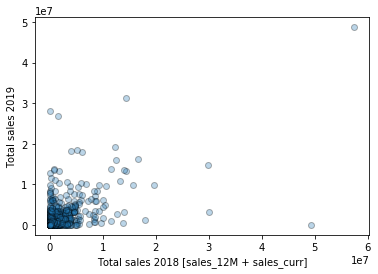

In [27]:
## try with removal of outliers
plt.scatter((full_df.fillna(0)['sales_12M_2018']+full_df.fillna(0)['sales_curr']), full_df.fillna(0)['sales_12M_2019'], alpha=0.3, edgecolor='black')
plt.xlabel('Total sales 2018 [sales_12M + sales_curr]')
plt.ylabel('Total sales 2019')
#plt.savefig('fig_1_1012_totalsales_rem2.png')

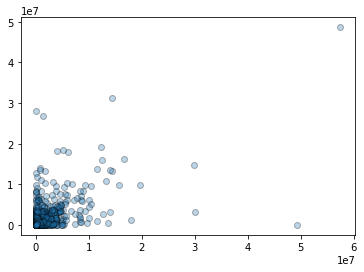

In [28]:
plt.scatter((full_df['total_sales']), full_df.fillna(0)['sales_12M_2019'], alpha=0.3, edgecolor='black')


In [33]:
# get maximum values
# get index of maximum values for sum sales_12M + sales_curr
sum_col = full_df.fillna(0)['sales_12M_2018']+full_df.fillna(0)['sales_curr']
#column = full_df["sales_12M_2018"]
max_value = sum_col.idxmax()
max_value


9888

In [396]:
#full_df.loc[9888]['total_sales']

In [36]:
np.shape(full_df)

(10003, 61)

In [35]:
full_df = full_df.drop(max_value)

In [421]:
# remove everything that is above 200k
#np.shape(df)
sum_col = full_df.fillna(0)['sales_12M_2018']+full_df.fillna(0)['sales_curr']
#column=full_df['sales_12M_2018']
max_value = sum_col.idxmax()
max_value


9888

In [970]:
sum_col.loc[9888]

49288520.5

In [971]:
full_df = full_df.drop(max_value)

In [972]:
sum_col = full_df.fillna(0)['sales_12M_2018']+full_df.fillna(0)['sales_curr']
#column=full_df['sales_12M_2018']
max_value = sum_col.idxmax()
max_value

4667

In [280]:
full_df['sales_12M_2018'].loc[4667]

29963424.5

In [281]:
sum_df = full_df['sales_curr']+full_df['sales_12M_2018']

In [282]:
sum_df.loc[4667]

nan

In [283]:
full_df = full_df.drop(max_value)

In [593]:
#full_df = full_df.drop(max_value)

In [36]:
np.shape(full_df)

(10003, 61)

Text(0, 0.5, 'Total Sales next Year')

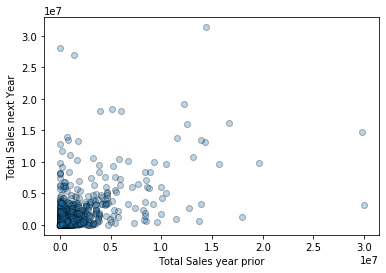

In [37]:
#check removal
plt.scatter(full_df.fillna(0)['sales_12M_2018']+full_df.fillna(0)['sales_curr'], full_df['sales_12M_2019'], alpha=0.3, edgecolor='black')
plt.xlabel('Total Sales year prior')
plt.ylabel('Total Sales next Year')
#plt.savefig('fig_2.png')

In [38]:
np.shape(full_df)

(10003, 61)

Text(0, 0.5, 'Total sales next year')

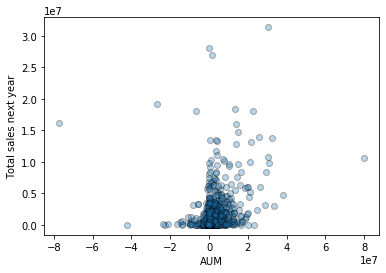

In [37]:
# check the distribution of AUM and total sales next year
plt.scatter(full_df['AUM'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('AUM')
plt.ylabel('Total sales next year')
#plt.savefig('fig_2_1_AUM.png')


In [42]:
np.shape(full_df)

(10001, 61)

In [39]:
column=full_df['AUM']
max_value = column.idxmax()
min_value = column.idxmin()

In [40]:
full_df.loc[max_value]['AUM']
full_df.loc[min_value]['AUM']

-77136098.36

In [41]:
#remove hisest value for AUM
full_df = full_df.drop(max_value)
full_df = full_df.drop(min_value)

Text(0, 0.5, 'Total sales next year')

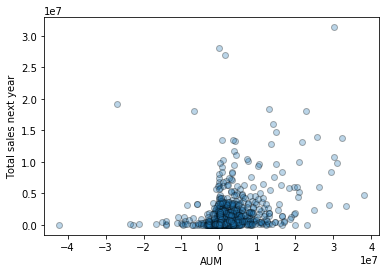

In [40]:
# check the distribution of AUM and total sales next year
plt.scatter(full_df['AUM'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('AUM')
plt.ylabel('Total sales next year')
#plt.savefig('fig_3_1012_AUM_pos_rem2.png')


In [502]:
column=full_df['AUM']
max_value = column.idxmax()
#full_df = full_df.drop(max_value)
max_value

1783

In [503]:
full_df.loc[max_value]['AUM']

77136098.36

In [504]:
full_df=full_df.drop(max_value)

In [1434]:
np.shape(full_df)

(10001, 61)

Text(0, 0.5, 'Total sales next year')

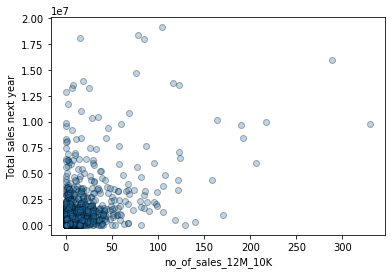

In [98]:
##check attribute# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])
plt.scatter(full_df.fillna(0)['no_of_sales_12M_10K'], full_df.fillna(0)['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('no_of_sales_12M_10K')
plt.ylabel('Total sales next year')

Text(0, 0.5, 'Total sales 2019')

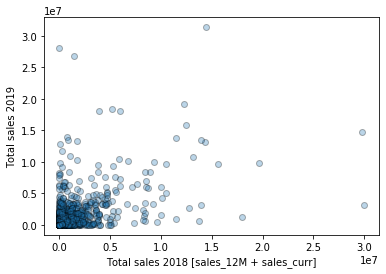

In [42]:
# remove max sales 2019
plt.scatter(full_df.fillna(0)['total_sales'], full_df.fillna(0)['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('Total sales 2018 [sales_12M + sales_curr]')
plt.ylabel('Total sales 2019')
#plt.savefig('fig_2_1012_totalsales_rem2019_3.png')

In [52]:
np.shape(full_df)

(9998, 61)

In [100]:
#column.describe()

In [49]:
##remove the two max values for sales_2019
column=full_df['sales_12M_2019']
max_value = column.idxmax()
#max_value = np.argmax(column)
max_value
#max(full_df['sales_12M_2019'])

4243

In [50]:
full_df.loc[max_value]['sales_12M_2019']

26884452.697203

In [51]:
full_df = full_df.drop(max_value)

Text(0, 0.5, 'Total sales next year')

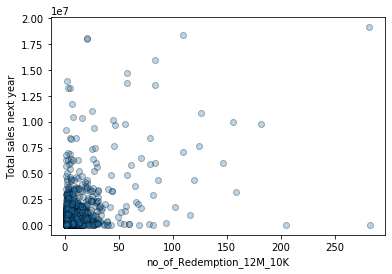

In [53]:
##check attribute# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])
plt.scatter(full_df['no_of_Redemption_12M_10K'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('no_of_Redemption_12M_10K')
plt.ylabel('Total sales next year')

In [106]:
column=full_df['sales_12M_2019']
max_value=column.idxmax()
full_df.loc[max_value]['sales_12M_2019']

19140606.52

In [107]:
full_df = full_df.drop(max_value)

Text(0, 0.5, 'Total sales next year')

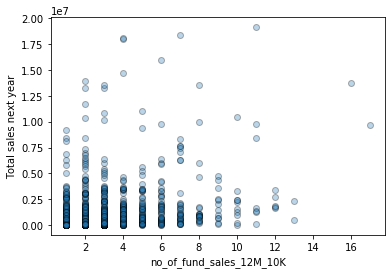

In [54]:
##check attribute# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])
plt.scatter(full_df['no_of_fund_sales_12M_10K'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('no_of_fund_sales_12M_10K')
plt.ylabel('Total sales next year')

Text(0, 0.5, 'Total sales next year')

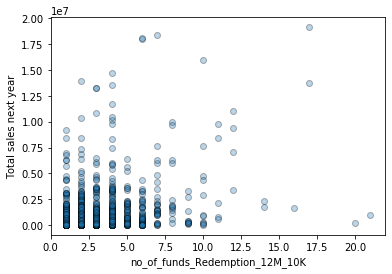

In [55]:
##check attribute# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])
plt.scatter(full_df['no_of_funds_Redemption_12M_10K'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('no_of_funds_Redemption_12M_10K')
plt.ylabel('Total sales next year')

Text(0, 0.5, 'Total sales next year')

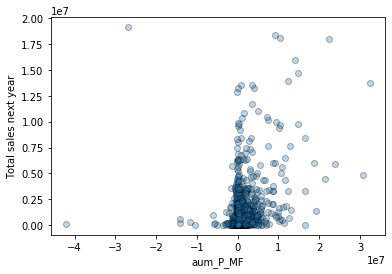

In [56]:
##check attribute# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])
plt.scatter(full_df['aum_P_MF'], full_df['sales_12M_2019'], alpha=0.3, edgecolors='black')
plt.xlabel('aum_P_MF')
plt.ylabel('Total sales next year')

In [45]:
np.shape(full_df)

(10001, 61)

#### [back to top](#Index)
# AUM 

In [43]:
def zero_filler(x):
    if x <0:
        return 0
    else:
        return x

count    9.416000e+03
mean     4.827046e+05
std      1.888809e+06
min      0.000000e+00
25%      0.000000e+00
50%      2.139135e+03
75%      1.743492e+05
max      3.799169e+07
Name: AUM, dtype: float64

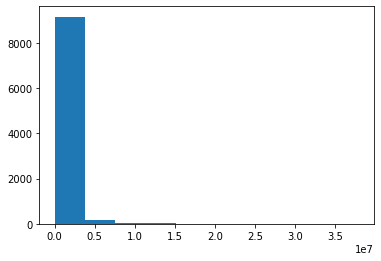

In [44]:
# convert negative values of AUM to zero (before data split?)
#plt.hist(full_df['AUM'], bins=100)
full_df['AUM'] = full_df['AUM'].apply(zero_filler)
#negative_to_zero(full_df['AUM'])
plt.hist(full_df['AUM'])
full_df['AUM'].describe()

In [45]:
aum_cols = [i for i in full_df.columns if i.startswith('aum')]
for col in aum_cols:
    full_df[col] = full_df[col].apply(zero_filler)


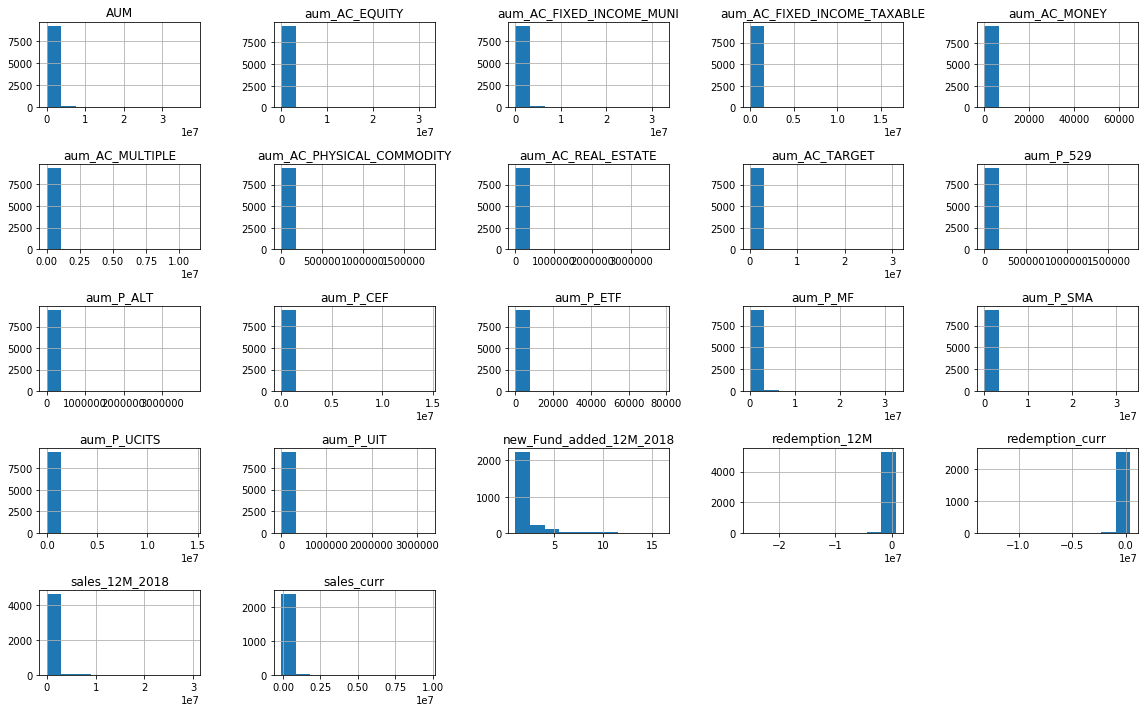

In [46]:
# histogram of each AUM based indicator
full_df[['AUM', 'sales_curr', 'sales_12M_2018',
       'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
       'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT']].hist(figsize = (16,10))
plt.tight_layout()

#### [back to top](#Index)
# Data split

In [47]:
## Split Train and Test data
X= full_df.drop(['sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019', 'refresh_date_2018', 'CONTACT_ID','sales_curr','sales_12M_2018' ], axis=1)
y_reg = full_df['sales_12M_2019']
y_cl = full_df['new_Fund_added_12M_2019']
#y = df['sales_12M_2019']

#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state=24)
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.25, random_state=15, stratify=y_reg.isnull()
)
y_train_cl, y_test_cl = y_cl[y_train_reg.index], y_cl[y_test_reg.index]

In [48]:
np.shape(X_train)
#np.shape(X)

(7500, 54)

In [49]:
print(X_train.columns)

Index(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
       'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
       'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
       'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
       'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
       'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
       'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
       'cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount', 'cha_Dual',
       'cha_Fee-Based Adviser', 'cha_Independent Dealer',
       'cha_Internat

In [50]:
# # # #check the amount of zeros or NAs in the dataset
# np.shape(y_train_reg)[0]
# y_train_reg.head(20)
# prop_na_ytr = y_train_reg.isna().sum()/np.shape(y_train_reg)[0]
# prop_na_ytr
# np.shape(y_test_reg)[0]
# prop_na_yte = y_test_reg.isna().sum()/np.shape(y_test_reg)[0]
# prop_na_ytr
# prop_na_yte
#X_train.columns

#### [back to top](#Index)

## Pipeline
The idea is to build a pipeline so that we can apply it several times with few modifications each time.
So the pipeline would consit of all the pre-processing steps plus the model regressor, which we might want
to test different ones.


In [51]:
## Pipeline
extract_columns_trans = FunctionTransformer(extract_columns, validate=False)
fillna_values_trans = FunctionTransformer(fillna_values, validate=False)
negative_to_zero_trans = FunctionTransformer(negative_to_zero)
bin_y_class_trans = FunctionTransformer(bin_y_class)

In [52]:
## prepare data for pipeline
targ_pipe = Pipeline([
    ('fillna_values_trans', fillna_values_trans),
    ('negative_to_tezo', negative_to_zero_trans)
    #('num_imp', SimpleImputer(strategy='median'))
])
class_targ_pipe = Pipeline([
    ('fillna_values_trans', fillna_values_trans),
    ('bin_y_class_trans', bin_y_class_trans),
])



#y_train = targ_pipe.fit_transform(y_train.values.reshape(-1,1)) # fit and transform TRAINING
#y_train = pd.Series(y_train.flatten(), index=X_train.index)
#y_test = pd.Series(targ_pipe.transform(y_test.values.reshape(-1,1)).flatten(), index=X_test.index) # transform only TESTING



In [52]:
#targ_pipe.fit(y_train_cl.to_frame())

In [53]:
#pd.Series(targ_pipe.transform(y_train_reg.to_frame()).reshape(1,-1).flatten(), index=y_train_reg.index)

In [54]:
#pd.Series(targ_pipe.transform(y_train_cl.to_frame()).reshape(1,-1).flatten(), index=y_train_cl.index)

In [524]:
# pd.Series(targ_pipe.transform(y_train_cl).reshape(-1,1).flatten(), index=y_train_cl.index)
# y_train_cl
#y_train_cl.describe()
#type(y_train_cl)
#type(y_train_reg)

#### Fit and transform training data

In [53]:
y_train_reg = targ_pipe.fit_transform(y_train_reg) # fit and transform TRAINING
y_train_cl =  class_targ_pipe.fit_transform(y_train_cl)

#### Transform test data

In [54]:
y_test_reg = targ_pipe.transform(y_test_reg) # transform only TESTING
y_test_cl = class_targ_pipe.transform(y_test_cl) # transform only TESTING

#### Without split

In [258]:
# ##fit and tranform them all, for using cross validation
# y_reg = targ_pipe.transform(y_reg)
# y_cl = class_targ_pipe.transform(y_cl)

## Make pipeline for features

In [56]:
# t = [('cat', OneHotEncoder(), categorical_ix), ('num', MinMaxScaler(), numerical_ix)]
# col_transform = ColumnTransformer(transformers=t)
# # define the model
# model = SVR(kernel='rbf',gamma='scale',C=100)
# # define the data preparation and modeling pipeline
# pipeline = Pipeline(steps=[('prep',col_transform), ('m', model)])

In [55]:
## Pipeline
feat_pipe = Pipeline([
    #('extract_columns_trans', extract_columns_trans),
    ('fillna_values_trans', fillna_values_trans),
    ('StandardScaler', StandardScaler())
])

In [56]:
selector = ColumnTransformer([
    #('extract_columns_trans', extract_columns_trans, all_cols),
    ('scalar', feat_pipe, cols_transformer)
], remainder='passthrough')

In [217]:
#selector.fit(X_train)

In [57]:
selector.get_feature_names

<bound method ColumnTransformer.get_feature_names of ColumnTransformer(remainder='passthrough',
                  transformers=[('scalar',
                                 Pipeline(steps=[('fillna_values_trans',
                                                  FunctionTransformer(func=<function fillna_values at 0x0000022D47AD00D0>)),
                                                 ('StandardScaler',
                                                  StandardScaler())]),
                                 ['no_of_sales_12M_1', 'no_of_Redemption_12M_1',
                                  'no_of_sales_12M_10K',
                                  'no_of_Redemption_12M_10K',
                                  'no_of_funds_sold_12M_1',
                                  'no_of_funds_red...
                                  'no_of_assetclass_Redemption_12M_10K',
                                  'No_of_fund_curr', 'No_of_asset_curr', 'AUM',
                                  'redemption_curr', 'red

In [58]:
train_array = selector.fit(X_train, y_train_reg).transform(X_train)
train_array[:2]
#np.shape(train_array)

array([[ 0.13988734,  0.70226674, -0.02613719,  0.82854703,  2.36079053,
         2.61799233,  0.33191461,  1.03478106,  2.22432312,  2.01489308,
         0.88497734,  2.11612858,  0.89782762,  1.05336366,  4.08582926,
        -1.76488837, -0.879439  ,  0.42151359, -0.16428376,  5.31769504,
        -0.08122941, -0.01154778, -0.11007536, -0.0439088 , -0.02777233,
        -0.03831168, -0.0768027 , -0.02433484, -0.08447114, -0.01853861,
         1.11349585,  5.03848546, -0.02077645, -0.07282116, -0.09792738,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  1.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         1.        ,  0.        ,  0.        ,  0.        ],
       [-0.20326604, -0.09692914, -0.22255892, -0.20337216, -0.56746876,
        -0.6179588 , -0.43028979, -0.4436184 , -0.77827288, -0.86042209,
        -0.53113746, -0.55890333, -0.35998636,  0.08815566, -0.

In [61]:
# train_array = feat_pipe.fit(X_train, y_train_reg).transform(X_train)
# train_array[:2]

In [59]:
X_train_prepared = pd.DataFrame(
    train_array,
    index=X_train.index,
    columns=COLS_TO_KEEP
)


In [60]:
#y_train.describe()
X_train_prepared.head(5)

In [61]:
X_test_prepared = pd.DataFrame(
    selector.transform(X_test),
    index=X_test.index,
    columns=COLS_TO_KEEP
)

In [62]:
X_test_prepared.head(5)


In [63]:
# for all features (without split)
X_prepared = pd.DataFrame(
    selector.transform(X),
    index= X.index,
    columns=COLS_TO_KEEP
)

In [64]:
X_prepared.tail(5)

#### [back to top](#Index)
# Feature selection


In [65]:
#X_train_prepared.head(5)
full_df.columns

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'total_sales'

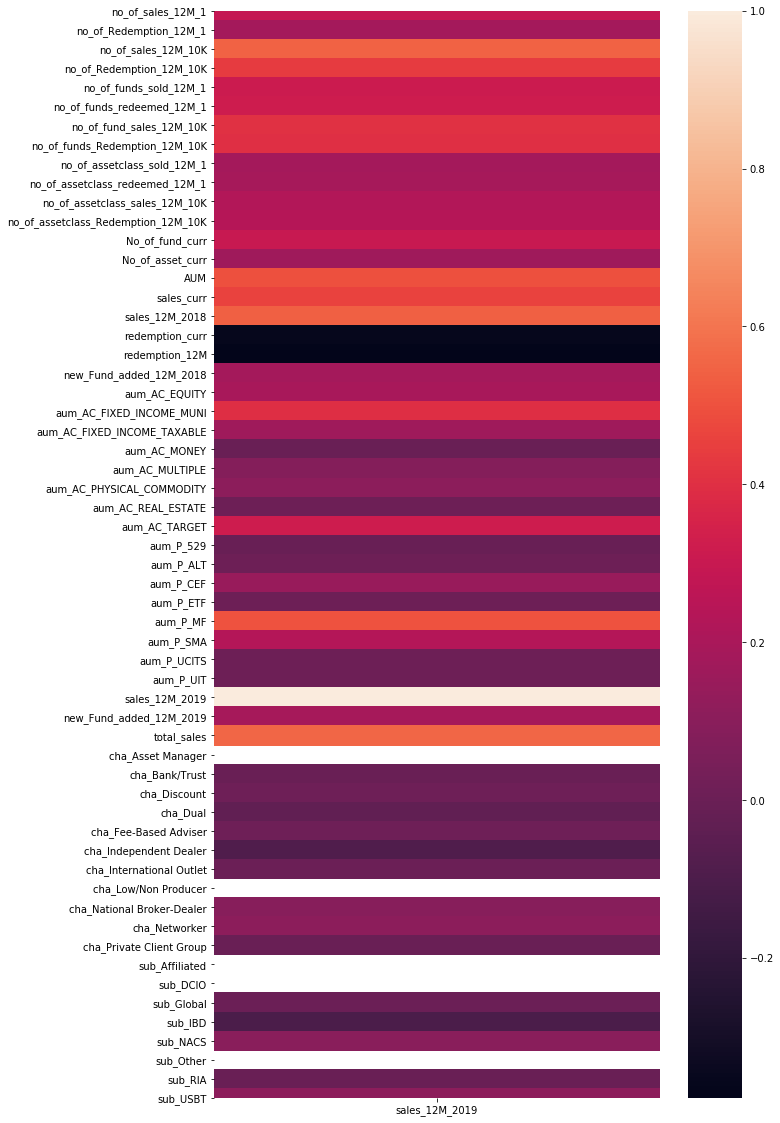

In [66]:

##heatmap with more data
corr = full_df.corr()
plt.figure(figsize=(10,20))
sns.heatmap(corr[['sales_12M_2019']])
plt.savefig('correlation.png',bbox_inches='tight' )

In [67]:
print(X_train.columns)

Index(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
       'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
       'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
       'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
       'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
       'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
       'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
       'cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount', 'cha_Dual',
       'cha_Fee-Based Adviser', 'cha_Independent Dealer',
       'cha_Internat

In [70]:
## vizual selection of features based on above heatmap colors
#df['no_of_Redemption_12M_1','no_of_sales_12M_1']
#heat_map_cols =(['no_of_sales_12M_1', 'no_of_Redemption_12M_1','no_of_sales_12M_10K','no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K','no_of_funds_Redemption_12M_10K', 'AUM','total_sales' ])
#heat_map_cols=(['total_sales', ])

#Selection based on GBRegressor of feat_imp (minus [sales_curr and sales_12M_2018])
# heat_map_cols=(['no_of_sales_12M_10K','no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K','no_of_funds_Redemption_12M_10K','no_of_assetclass_sales_12M_10K',
#                'no_of_assetclass_Redemption_12M_10K','AUM','redemption_curr','redemption_12M','new_Fund_added_12M_2018','aum_AC_FIXED_INCOME_MUNI','aum_AC_PHYSICAL_COMMODITY',
#                'aum_AC_TARGET', 'aum_P_CEF','aum_P_MF','aum_P_SMA','aum_P_UCITS','total_sales', 'total_redemptions'])
# Selection to to account for total_redemptions:
# heat_map_cols=(['no_of_sales_12M_10K','no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K','no_of_funds_Redemption_12M_10K','no_of_assetclass_sales_12M_10K',
#                'no_of_assetclass_Redemption_12M_10K','AUM','new_Fund_added_12M_2018','aum_AC_FIXED_INCOME_MUNI','aum_AC_PHYSICAL_COMMODITY',
#                'aum_AC_TARGET', 'aum_P_CEF','aum_P_MF','aum_P_SMA','aum_P_UCITS','total_sales', 'total_redemptions'])
# Selection 2 (remove no_of_assetclass_sales_12M_10K and aum_AC_Target)
# heat_map_cols=(['no_of_sales_12M_10K','no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K','no_of_funds_Redemption_12M_10K',
#                'no_of_assetclass_Redemption_12M_10K','AUM','new_Fund_added_12M_2018','aum_AC_FIXED_INCOME_MUNI','aum_AC_PHYSICAL_COMMODITY',
#                'aum_P_CEF','aum_P_MF','aum_P_SMA','aum_P_UCITS','total_sales', 'total_redemptions'])

#Selection based on RFECV (1st round)
# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
#                'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K','no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
#                'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
#                'sales_12M_2018', 'redemption_curr', 'redemption_12M','new_Fund_added_12M_2018', 'aum_AC_FIXED_INCOME_MUNI','aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF',
#                'aum_P_ETF', 'aum_P_MF', 'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'cha_Asset Manager'])
# Selection 3
# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_funds_redeemed_12M_1',
#                'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K','no_of_assetclass_redeemed_12M_1',
#                'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr', 'AUM', 'sales_curr',
#                'sales_12M_2018', 'redemption_curr', 'redemption_12M','new_Fund_added_12M_2018', 'aum_AC_FIXED_INCOME_MUNI','aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF',
#                'aum_P_MF', 'aum_P_UCITS'])

#heat_map_cols =(['sales_curr','sales_12M_2018'])

# selection 4: can try selection 3 and remove features of 1 dollar
# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr', 'AUM', 'sales_curr',
#                'sales_12M_2018', 'redemption_curr', 'redemption_12M','new_Fund_added_12M_2018', 'aum_AC_FIXED_INCOME_MUNI','aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF',
#                'aum_P_MF', 'aum_P_UCITS'])

# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr', 'sales_curr',
#                'sales_12M_2018', 'redemption_curr', 'redemption_12M','new_Fund_added_12M_2018'])

# Selection 1 - RF
# heat_map_cols=(['no_of_sales_12M_1', 'no_of_Redemption_12M_1',
#        'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#        'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
#        'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
#        'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
#        'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
#        'sales_12M_2018', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MULTIPLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_TARGET',
#        'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA', 'cha_Fee-Based Adviser', 'cha_Independent Dealer',
#        'cha_National Broker-Dealer', 'cha_Networker',
#        'sub_IBD', 'sub_NACS', 'sub_RIA', 'sub_USBT'])

# Selection 2 - RF
# heat_map_cols=(['no_of_sales_12M_1', 'no_of_Redemption_12M_1',
#        'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#        'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
#        'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_redeemed_12M_1',
#        'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
#        'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
#        'sales_12M_2018', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MULTIPLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_TARGET',
#        'aum_P_529', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA'])
# Selection 3 - RF
# heat_map_cols=(['no_of_sales_12M_1', 'no_of_Redemption_12M_1',
#        'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#        'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
#        'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_redeemed_12M_1',
#        'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
#        'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
#        'sales_12M_2018', 'redemption_curr', 'redemption_12M',
#        'aum_AC_FIXED_INCOME_MUNI', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF'])
# Selection 4 - RF
# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#        'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
#        'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
#        'sales_12M_2018', 'redemption_curr', 'redemption_12M',
#        'aum_AC_FIXED_INCOME_MUNI', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF'])
# Selection 5 - RF
# heat_map_cols=(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#        'no_of_funds_sold_12M_1', 'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'AUM', 'sales_curr',
#        'sales_12M_2018', 'redemption_curr', 'redemption_12M',
#        'aum_AC_FIXED_INCOME_MUNI', 'aum_P_CEF', 'aum_P_MF'])

#Selection 6 - RF
# heat_map_cols=(['no_of_sales_12M_10K', 'AUM', 'sales_curr',
#        'sales_12M_2018','aum_P_MF'])

#Selection 7 (without outliers - just for testing)
# heat_map_cols=(['AUM', 'sales_curr',
#        'sales_12M_2018','aum_P_MF'])

####### Selection for GradientBoostingRegressor
# heat_map_cols =(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
#        'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_redeemed_12M_1', 'No_of_fund_curr',
#        'No_of_asset_curr', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MULTIPLE',
#        'aum_AC_PHYSICAL_COMMODITY',  'aum_AC_TARGET',
#        'aum_P_CEF', 'aum_P_MF', 'aum_P_SMA'])
#heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#       'aum_AC_FIXED_INCOME_MUNI', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF'])

################# Selection 06-12 (last one pleaseee)

# heat_map_cols = (['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
#        'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
#        'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
#        'No_of_asset_curr', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
#        'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA', 'cha_Independent Dealer','sub_IBD', 'sub_NACS'])
##Selection 2
# heat_map_cols = (['no_of_sales_12M_1', 'no_of_sales_12M_10K','no_of_Redemption_12M_10K', 
#        'no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
#        'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#        ])

## Selection 3
# heat_map_cols = ([ 'no_of_sales_12M_10K','no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'aum_AC_FIXED_INCOME_MUNI','aum_P_CEF'
#        ])

## Selection 4
# heat_map_cols = ([ 'no_of_sales_12M_10K','no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'aum_P_CEF'
#        ])
## Selection 5
# heat_map_cols = ([ 'no_of_sales_12M_10K','no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        ])
#Selection 6
# heat_map_cols = ([ 'no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018'
#        ])


### round with 2 outliers removal & nothing at AUM
# Selection 1
# heat_map_cols = (['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
#        'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K','no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
#        'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE','aum_AC_PHYSICAL_COMMODITY', 'aum_AC_TARGET',
#        'aum_P_ALT', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA'])

# # Selection 2
# heat_map_cols = (['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K','no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
#        'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI','aum_P_CEF', 'aum_P_MF'
#        ])

# # Selection 3
# heat_map_cols = (['no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K','no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'new_Fund_added_12M_2018','aum_P_CEF', 'aum_P_MF'
#        ])

# Selection 4
# heat_map_cols = ([ 'no_of_funds_Redemption_12M_10K','no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'aum_P_CEF', 'aum_P_MF'
#        ])

# #Selection 5
# heat_map_cols = ([ 'no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'aum_P_CEF', 'aum_P_MF'
#        ])

#Selection 6
# heat_map_cols = ([ 'no_of_funds_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#       'aum_P_MF'
#        ])

#Selection 7
# heat_map_cols = ([ 'AUM', 'sales_curr', 'sales_12M_2018',
#       'aum_P_MF'
#        ])

### Attempt with: 2 outliers removal + AUMs where negative == zero
# selection 1
# heat_map_cols = ([ 'no_of_sales_12M_10K','no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
#        'aum_AC_FIXED_INCOME_MUNI', 'aum_AC_MULTIPLE', 'aum_AC_PHYSICAL_COMMODITY', 
#        'aum_P_CEF', 'aum_P_MF'])

# selection 2
# heat_map_cols = ([ 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_Redemption_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',
#        'new_Fund_added_12M_2018', 'aum_AC_FIXED_INCOME_MUNI', 'aum_P_CEF', 'aum_P_MF'])

# selection 3
# heat_map_cols = ([ 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#         'AUM', 'sales_curr', 'sales_12M_2018', 'aum_P_CEF', 'aum_P_MF'])

# selection 4
#heat_map_cols = ([ 'no_of_fund_sales_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018',  'aum_P_MF'])

### Attempt: -2 outliers + total sales + AUM equal zero

# heat_map_cols = (['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
#        'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
#        'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
#        'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
#        'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
#        'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales'
#        ])

#Attempt 07.12.2020 - 2 outliers [total_sales] + total_sales + AUM = 0 

# heat_map_cols = (['no_of_Redemption_12M_1', 'no_of_Redemption_12M_10K', 
#        'no_of_fund_sales_12M_10K','no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'AUM', 'new_Fund_added_12M_2018',  'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF','aum_P_MF',
#        'total_sales'
#                  ])  


# heat_map_cols = (['no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'AUM', 'aum_P_MF', 'total_sales'
#                  ])  

#### Selection XGB (2 outliers)
# heat_map_cols = ([ 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
#        'AUM', 'redemption_12M','new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA', 'aum_P_UCITS', 'total_sales', 'cha_National Broker-Dealer'
#        ])

# heat_map_cols = ([ 'no_of_sales_12M_10K',  'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
#        'AUM', 'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA',  'total_sales', 'cha_National Broker-Dealer'
#        ])

# heat_map_cols = ([ 'no_of_sales_12M_10K',  'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K', 
#        'no_of_assetclass_Redemption_12M_10K',  'AUM', 'aum_P_CEF', 'total_sales'
#        ])

# heat_map_cols = ([ 'no_of_sales_12M_10K',  'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K', 
#        'no_of_assetclass_Redemption_12M_10K',  'total_sales'
#        ])

## Xgb 2 outliers + AUM zero

# heat_map_cols =(['total_sales','no_of_funds_Redemption_12M_10K','no_of_assetclass_Redemption_12M_10K',
#                 'AUM','no_of_Redemption_12M_10K','no_of_sales_12M_10K' ])

###################### potential winner!!!('xgb', XGBRegressor(max_depth=2, learning_rate=0.02, min_child_weight=1, gamma=0))

## Xgb 2 outliers total_Sales + 2 outliers AUM

# heat_map_cols =(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K',  'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
#        'AUM', 'redemption_curr', 'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE','aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_UCITS',  'total_sales'
#                 ])

# heat_map_cols =(['no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K',  'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'AUM', 'redemption_curr',  'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#         'total_sales'
#                 ])

# heat_map_cols =([    'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K',  'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'aum_P_CEF', 'aum_P_MF',
#         'total_sales'
#                 ])

## Attempt 2 out total_Sales + 2 out AUM + AUM = zero
# heat_map_cols =(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
#        'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K', 'AUM', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_P_CEF', 'aum_P_MF',
#        'aum_P_SMA', 'total_sales', 'cha_National Broker-Dealer'
#                 ])


## Initally select only the 10k features
# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K','no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr',
#        'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
#        'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
#        'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
#           ])

## select 1st 6 features
# heat_map_cols = (['total_sales', 'no_of_Redemption_12M_10K','no_of_funds_Redemption_12M_10K',
#                  'no_of_assetclass_Redemption_12M_10K', 'no_of_sales_12M_10K','aum_P_MF',
#                  'new_Fund_added_12M_2018','AUM'])

###### potencial winner ('xgb', XGBRegressor(max_depth = 7, min_child_weight= 5, eta= 0.005, subsample= 0.9, colsample_bytree =1.0, learning_rate=0.01))
# heat_map_cols = (['total_sales', 'no_of_Redemption_12M_10K','no_of_funds_Redemption_12M_10K',
#                  'no_of_assetclass_Redemption_12M_10K', 'AUM'])
##### potential winner with 0.47 on both sets:     ('xgb', XGBRegressor(max_depth = 4, min_child_weight= 6, eta= 0.3, subsample= 0.8, colsample_bytree =1.0, learning_rate=0.015))

# heat_map_cols = (['total_sales', 'no_of_Redemption_12M_10K','no_of_funds_Redemption_12M_10K',
#                  'no_of_assetclass_Redemption_12M_10K'])

# heat_map_cols = (['total_sales', 'no_of_Redemption_12M_10K', 'no_of_assetclass_Redemption_12M_10K'])


### one more: 2 outliers and aUm = zero with tunning of paremeters (minus 1 dollar)
#tunning first round:    ('xgb', XGBRegressor(max_depth = 2, min_child_weight= 5, eta= 0.3, subsample= 1.0, colsample_bytree =1.0, learning_rate=0.02))

# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K', 'no_of_fund_sales_12M_10K',
#        'no_of_funds_Redemption_12M_10K','no_of_assetclass_sales_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K','No_of_fund_curr',
#        'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
#        'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
#        'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
#        'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
#        'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
#        'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
#           ])

# heat_map_cols =([ 'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K','AUM', 'redemption_curr', 'redemption_12M',
#        'aum_AC_FIXED_INCOME_MUNI', 'aum_P_MF','aum_P_SMA', 'total_sales'
#           ])

# heat_map_cols =([ 'no_of_Redemption_12M_10K', 'no_of_funds_Redemption_12M_10K',
#        'no_of_assetclass_Redemption_12M_10K','AUM', 'aum_P_MF','aum_P_SMA', 'total_sales'
#           ])


####Selection based on color map!!!!!!!!!!!!!!!!!!!!!! caralho, é esse! removal of 2 total + 2 AUM [min & max] + AUM positive!
#    ('xgb', XGBRegressor(max_depth = 4, min_child_weight=3, eta= 0.3, subsample= 0.9,  colsample_bytree =1.0, learning_rate=0.015))
heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K','no_of_fund_sales_12M_10K',
                 'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales','new_Fund_added_12M_2018'])

# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])

# heat_map_cols =(['no_of_sales_12M_10K', 'no_of_fund_sales_12M_10K',
#                  'no_of_funds_Redemption_12M_10K','AUM', 'aum_P_MF', 'total_sales'])



In [71]:
print(X_train.columns)

Index(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
       'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
       'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
       'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
       'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
       'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
       'No_of_asset_curr', 'AUM', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
       'cha_Asset Manager', 'cha_Bank/Trust', 'cha_Discount', 'cha_Dual',
       'cha_Fee-Based Adviser', 'cha_Independent Dealer',
       'cha_Internat

In [72]:
#print(full_df.columns)
#print(X_train_prepared.columns)

In [73]:
## Select from X_test and train (and prepared)
X_train=X_train[heat_map_cols]
X_test=X_test[heat_map_cols]
X_train_prepared=X_train_prepared[heat_map_cols]
X_test_prepared=X_test_prepared[heat_map_cols]

In [74]:
## for all data
X_prepared = X_prepared[heat_map_cols]

In [75]:
X_train_prepared

#### [back to top](#Index)

## Modelling

In [76]:
def modified_log(x):
    x = np.where(x<0, 0, x)
    return np.log(x, where=x>0)

In [74]:
def modified_exp(x):
    x = np.where(x>15, 15, x)
    return np.expm1(x)

In [77]:
dtrain = xgb.DMatrix(X_train_prepared, label=y_train_reg)
dtest = xgb.DMatrix(X_test_prepared, label=y_test_reg)

In [98]:
# tunning parameters for xbr

params = {
    # Parameters that we are going to tune.
    'learning_rate':0.02,
    'max_depth':6,
    'min_child_weight': 1,
    'eta':.3,
    'subsample': 0.9,
    'colsample_bytree': 1,
    # Other parameters
    #'objective':'reg:linear',
    'eval_metric' : "mae",
    'num_boost_round': 25,
}
# grad = XGBRegressor(learning_rate =0.1,
#  n_estimators=1000,
#  max_depth=5,
#  min_child_weight=1,
#  gamma=0,
#  subsample=0.8,
#  colsample_bytree=0.8,
# # objective= 'binary:logistic',
#  nthread=4,
#  scale_pos_weight=1,
#  seed=27)
# num_boost_round= 999
# params['eval_metric'] = "mae"
#params

In [101]:
num_boost_round=900
model = xgb.train(
    params,
    dtrain,
    num_boost_round=num_boost_round,
    evals=[(dtest, "Test")],
    early_stopping_rounds=10
)

[12:50:35] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[0]	Test-mae:171359.54688
Will train until Test-mae hasn't improved in 10 rounds.
[1]	Test-mae:169302.78125
[2]	Test-mae:167068.14062
[3]	Test-mae:165149.01562
[4]	Test-mae:163381.89062
[5]	Test-mae:162042.68750
[6]	Test-mae:160801.03125
[7]	Test-mae:158927.28125
[8]	Test-mae:157778.82812
[9]	Test-mae:156684.29688
[10]	Test-mae:155797.37500
[11]	Test-mae:154774.14062
[12]	Test-mae:154020.68750
[13]	Test-mae:153269.51562
[14]	Test-mae:152365.48438
[15]	Test-mae:151596.93750
[16]	Test-mae:151031.48438
[17]	Test-mae:150658.28125
[18]	Test-mae:150016.70312
[19]	Test-mae:149565.00000
[20]	Test-mae:149106.

In [103]:
cv_results = xgb.cv(
    params,
    dtrain,
    #num_boost_round=num_boost_round,
    seed=42,
    nfold=5,
    metrics={'mae'},
    early_stopping_rounds=10
)
cv_results
cv_results['test-mae-mean'].min()

[12:51:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only u

188148.58125

In [104]:
gridsearch_params = [
    (max_depth, min_child_weight)
    for max_depth in range(2,12)
    for min_child_weight in range(1,8)
]


In [105]:
min_mae = float("Inf")
best_params = None
for max_depth, min_child_weight in gridsearch_params:
    print("CV with max_depth={}, min_child_weight={}".format(
                             max_depth,
                             min_child_weight))
    # Update our parameters
    params['max_depth'] = max_depth
    params['min_child_weight'] = min_child_weight
    # Run CV
    cv_results = xgb.cv(
        params,
        dtrain,
        #num_boost_round=num_boost_round,
        seed=42,
        nfold=5,
        metrics={'mae'},
        early_stopping_rounds=10
    )
    # Update best MAE
    mean_mae = cv_results['test-mae-mean'].min()
    boost_rounds = cv_results['test-mae-mean'].argmin()
    print("\tMAE {} for {} rounds".format(mean_mae, boost_rounds))
    if mean_mae < min_mae:
        min_mae = mean_mae
        best_params = (max_depth,min_child_weight)
print("Best params: {}, {}, MAE: {}".format(best_params[0], best_params[1], min_mae))

CV with max_depth=2, min_child_weight=1
[12:51:10] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:10] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:10] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be ac

	MAE 187994.10625 for 28 rounds
CV with max_depth=2, min_child_weight=2
[12:51:11] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:11] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:11] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might no

	MAE 188027.215625 for 28 rounds
CV with max_depth=2, min_child_weight=7
[12:51:13] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:13] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:13] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might n

	MAE 178815.95625 for 32 rounds
CV with max_depth=3, min_child_weight=5
[12:51:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might no

	MAE 177005.53125 for 35 rounds
CV with max_depth=4, min_child_weight=3
[12:51:21] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:21] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:21] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might no

	MAE 177608.94375 for 32 rounds
CV with max_depth=5, min_child_weight=1
[12:51:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:51:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might no

... (5 outputs left out)

	MAE 176399.715625 for 30 rounds
CV with max_depth=9, min_child_weight=3
[12:52:01] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:01] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:01] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might n

	MAE 176280.8375 for 31 rounds
CV with max_depth=10, min_child_weight=1
[12:52:09] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:09] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:09] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might no

	MAE 176678.43125 for 31 rounds
CV with max_depth=10, min_child_weight=6
[12:52:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:17] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might n

	MAE 177046.025 for 29 rounds
CV with max_depth=11, min_child_weight=4
[12:52:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:25] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not

In [106]:
params['max_depth'] = 8
params['min_child_weight'] = 7

In [107]:
gridsearch_params = [
    (subsample, colsample)
    for subsample in [i/10. for i in range(7,11)]
    for colsample in [i/10. for i in range(7,11)]
]

In [108]:
min_mae = float("Inf")
best_params = None
# We start by the largest values and go down to the smallest
for subsample, colsample in reversed(gridsearch_params):
    print("CV with subsample={}, colsample={}".format(
                             subsample,
                             colsample))
    # We update our parameters
    params['subsample'] = subsample
    params['colsample_bytree'] = colsample
    # Run CV
    cv_results = xgb.cv(
        params,
        dtrain,
        num_boost_round=num_boost_round,
        seed=42,
        nfold=5,
        metrics={'mae'},
        early_stopping_rounds=10
    )
    # Update best score
    mean_mae = cv_results['test-mae-mean'].min()
    boost_rounds = cv_results['test-mae-mean'].argmin()
    print("\tMAE {} for {} rounds".format(mean_mae, boost_rounds))
    if mean_mae < min_mae:
        min_mae = mean_mae
        best_params = (subsample,colsample)
print("Best params: {}, {}, MAE: {}".format(best_params[0], best_params[1], min_mae))

CV with subsample=1.0, colsample=1.0
[12:52:53] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:53] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:53] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accur

	MAE 177359.1125 for 29 rounds
CV with subsample=1.0, colsample=0.9
[12:52:54] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:54] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:52:54] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be

	MAE 176417.225 for 30 rounds
CV with subsample=0.9, colsample=0.8
[12:53:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:53:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:53:00] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be 

	MAE 176993.453125 for 34 rounds
CV with subsample=0.8, colsample=0.7
[12:53:05] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:53:05] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not be used.

  This may not be accurate due to some parameters are only used in language bindings but
  passed down to XGBoost core.  Or some parameters are not used but slip through this
  verification. Please open an issue if you find above cases.


[12:53:05] WARNING: C:\Users\Administrator\workspace\xgboost-win64_release_1.2.0\src\learner.cc:516: 
Parameters: { num_boost_round } might not 

	MAE 177722.053125 for 28 rounds
Best params: 0.9, 1.0, MAE: 176004.6


In [109]:
params['subsample'] = 0.9
params['colsample_bytree'] = 1.

In [1478]:
# This can take some time…
min_mae = float("Inf")
best_params = None
for eta in [.6,.5,.4,.3, .2, .1, .05, .01, .005]:
    
    print("CV with eta={}".format(eta))
    # We update our parameters
    params['eta'] = eta
    # Run and time CV
    %time cv_results = xgb.cv(params,dtrain,num_boost_round=num_boost_round,seed=42,nfold=5,metrics=['mae'], early_stopping_rounds=10)
    # Update best score
    mean_mae = cv_results['test-mae-mean'].min()
    boost_rounds = cv_results['test-mae-mean'].argmin()
    print("\tMAE {} for {} rounds\n".format(mean_mae, boost_rounds))
    if mean_mae < min_mae:
        min_mae = mean_mae
        best_params = eta
print("Best params: {}, MAE: {}".format(best_params, min_mae))

CV with eta=0.6
Wall time: 493 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.5


Wall time: 507 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.4
Wall time: 530 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.3
Wall time: 563 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.2
Wall time: 525 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.1
Wall time: 576 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.05
Wall time: 522 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.01
Wall time: 552 ms
	MAE 186906.8875 for 26 rounds

CV with eta=0.005
Wall time: 533 ms
	MAE 186906.8875 for 26 rounds

Best params: 0.6, MAE: 186906.8875


In [110]:
params['eta'] = .3
params

{'learning_rate': 0.02,
 'max_depth': 8,
 'min_child_weight': 7,
 'eta': 0.3,
 'subsample': 0.9,
 'colsample_bytree': 1.0,
 'eval_metric': 'mae',
 'num_boost_round': 25}

In [1480]:
print("Best MAE: {:.2f} with {} rounds".format(
                 model.best_score,
                 model.best_iteration+1))

Best MAE: 150964.80 with 35 rounds


In [633]:
# grad.fit(X_train_prepared,y_train_reg)
# grad.best_params_, grad.best_score_

In [376]:
# try Gridsearch for best parameters: max_depth and min_child_weight
# params = {'max_depth':[2,3,4],
#  'min_child_weight':[1,2]}
# grad = XGBRegressor()
# #grad = GradientBoostingRegressor()
# #grad.fit(X_train_prepared,y_train_reg)
# grad_grid = GridSearchCV(grad, param_grid=params)
# grad_grid.fit(X_train_prepared, y_train_reg)

In [637]:
# # try Gridsearch for best parameters: gamma
# params = {'gamma':[i/10.0 for i in range(0,5)]}
# grad = XGBRegressor()
# #grad = GradientBoostingRegressor()
# #grad.fit(X_train_prepared,y_train_reg)
# grad_grid = GridSearchCV(grad, param_grid=params)
# grad_grid.fit(X_train_prepared, y_train_reg)

In [635]:
# params = {'learning_rate':[i/100.0 for i in range(0,20)]}
# grad = XGBRegressor()
# #grad = GradientBoostingRegressor()
# #grad.fit(X_train_prepared,y_train_reg)
# grad_grid = GridSearchCV(grad, param_grid=params)
# grad_grid.fit(X_train_prepared, y_train_reg)

In [636]:
#grad_grid.cv_results_
#grad_grid.best_params_, grad_grid.best_score_


In [261]:
#grad_grid.score(X_train_prepared, y_train_reg)

In [262]:
#grad_grid.score(X_test_prepared, y_test_reg)

In [263]:
#grad_grid.best_estimator_

In [78]:
## Test some regressors
feat_pipe = Pipeline([
    #('extract_columns_trans', extract_columns_trans),
    #('fillna_values_trans', fillna_values_trans),
    #('StandardScaler', StandardScaler()),
    #('select', SelectFromModel(DecisionTreeRegressor())),
    #('PCA', PCA(0.98)),
    #('tree', DecisionTreeRegressor(max_depth=5))
    #('lasso', Lasso(max_iter=1000000, alpha=0.1, )),
    #('ridge', Ridge(alpha=10))
    #('lr', LinearRegression())
    #('nmf', NMF(n_components=2, init='random', random_state=0)),
    #('gradient', GradientBoostingRegressor(learning_rate=0.02, max_depth=3, n_estimators=1000))
    #('ada', AdaBoostRegressor())
    #('forest', RandomForestRegressor(n_estimators=100))
    #('ridgecv', RidgeCV(alphas=[1,10, 100,10000
    #('rfecv', RFECV(GradientBoostingRegressor(learning_rate=0.02, max_depth=2),min_features_to_select=1))
    #('forest', RandomForestRegressor(n_estimators=400, max_features=0.5, max_depth=4, min_samples_leaf=2))
    #('xgb', XGBRegressor(max_depth=3, learning_rate=0.02, min_child_weight=1, gamma=0))
    ('xgb', XGBRegressor(max_depth = 4, min_child_weight=3, eta= 0.3, subsample= 1.0,  colsample_bytree =1.0, learning_rate=0.015))
])
        


In [1482]:
# ## For linear regressor : with log transform
# ttr = TransformedTargetRegressor(
#         #Ridge(),
#         #LinearRegression(),
#         #GradientBoostingRegressor(learning_rate=0.02, max_depth=2),
#         RidgeCV(alphas=[0.1, 1,10, 100,10000]), 
#         #Lasso(max_iter=100000, alpha=0.01),
#         func=np.log1p, 
#         inverse_func=modified_exp, 
#         check_inverse=False
# )

In [1483]:
#ttr.fit(X_train_prepared, y_train_reg)

In [1484]:
#ttr.score(X_train_prepared,y_train_reg)

In [650]:
#ttr.score(X_test_prepared, y_test_reg)

In [79]:
## for data split
feat_pipe.fit(X_train_prepared, y_train_reg)

Pipeline(steps=[('xgb',
                 XGBRegressor(base_score=0.5, booster='gbtree',
                              colsample_bylevel=1, colsample_bynode=1,
                              colsample_bytree=1.0, eta=0.3, gamma=0, gpu_id=-1,
                              importance_type='gain',
                              interaction_constraints='', learning_rate=0.015,
                              max_delta_step=0, max_depth=4, min_child_weight=3,
                              missing=nan, monotone_constraints='()',
                              n_estimators=100, n_jobs=0, num_parallel_tree=1,
                              random_state=0, reg_alpha=0, reg_lambda=1,
                              scale_pos_weight=1, subsample=1.0,
                              tree_method='exact', validate_parameters=1,
                              verbosity=None))])

In [80]:
scores_all_split = cross_validate(feat_pipe, X_train_prepared, y_train_reg, return_train_score=True)
scores_all_split

{'fit_time': array([0.11403084, 0.09911299, 0.10020065, 0.11450577, 0.10571742]),
 'score_time': array([0.0029912 , 0.        , 0.        , 0.00398946, 0.00902295]),
 'test_score': array([0.31200306, 0.3332328 , 0.46125661, 0.14944731, 0.14018808]),
 'train_score': array([0.53604776, 0.46988154, 0.46831996, 0.61536964, 0.48730491])}

In [81]:

feat_pipe.score(X_train_prepared, y_train_reg)

0.5111162257787103

In [82]:
feat_pipe.score(X_test_prepared, y_test_reg)

0.5151844637390244

In [83]:
X_train_prepared
X_test_prepared

In [413]:
# check for PCA componets
# n_pcs=feat_pipe[0].n_components_
# most_important = [np.abs(feat_pipe[0].components_[i]).argmax() for i in range(n_pcs)]
# most_important

In [412]:
# select= X_train.iloc[:,most_important]
# print(select.columns)
# np.shape(select)

In [705]:
# try to see which features were selected:
#X_select = feat_pipe.transform(X_train_prepared)

In [198]:
# export first results from RFECV
#pd.DataFrame(A).to_csv(path_or_buf='columns_1st_RFECV',index=False)
# export columns of X_train_prepared to compare
#X_test_prepared.columns().to_csv(path_or_buf='columns_names', index=False)

In [338]:
# A= feat_pipe[0].get_support()
# A


In [339]:
# # new_X_trained = X_train_prepared[A==True]
# new_X = X_train_prepared[A.index[X_train_prepared]]
#print(type(X_train_prepared))
#new_x = X_train_prepared[A==True]
#new_X_train_prepared = X_train_prepared[X_train_prepared.columns[A]] 
#new_X_test_prepared = X_test_prepared[X_test_prepared.columns[A]]

In [659]:
#print(new_X_train_prepared.columns)

In [341]:
#print(new_X_test_prepared['cha_Asset Manager'])

In [461]:
# for Lasso
# lasso = Lasso().fit(X_train_prepared, y_train_reg)
# print("Number of features used:", np.sum(lasso.coef_!=0))

In [84]:
# for forest
#feat_pipe[3].feature_importances_

d = {'Stats':X_train_prepared.columns,'FI':feat_pipe[0].feature_importances_}
df2 = pd.DataFrame(d)
#plot_feature_importances(forest)
df2
#df2.to_csv(path_or_buf='file_feat_importance_Xgb_1112',index=False)

,Stats,FI
0,no_of_sales_12M_10K,0.126016
1,no_of_Redemption_12M_10K,0.140258
2,no_of_fund_sales_12M_10K,0.061433
3,no_of_funds_Redemption_12M_10K,0.155925
4,AUM,0.064780
5,aum_P_MF,0.077884
6,total_sales,0.324448
7,new_Fund_added_12M_2018,0.049256


In [108]:
# #TRy graph with feature importance
# feat_imp = pd.Series(feat_pipe[0].booster().get_fscore()).sort_values(ascending=False)
# feat_imp.plot(kind='bar', title='Feature Importances')
# plt.ylabel('Feature Importance Score')

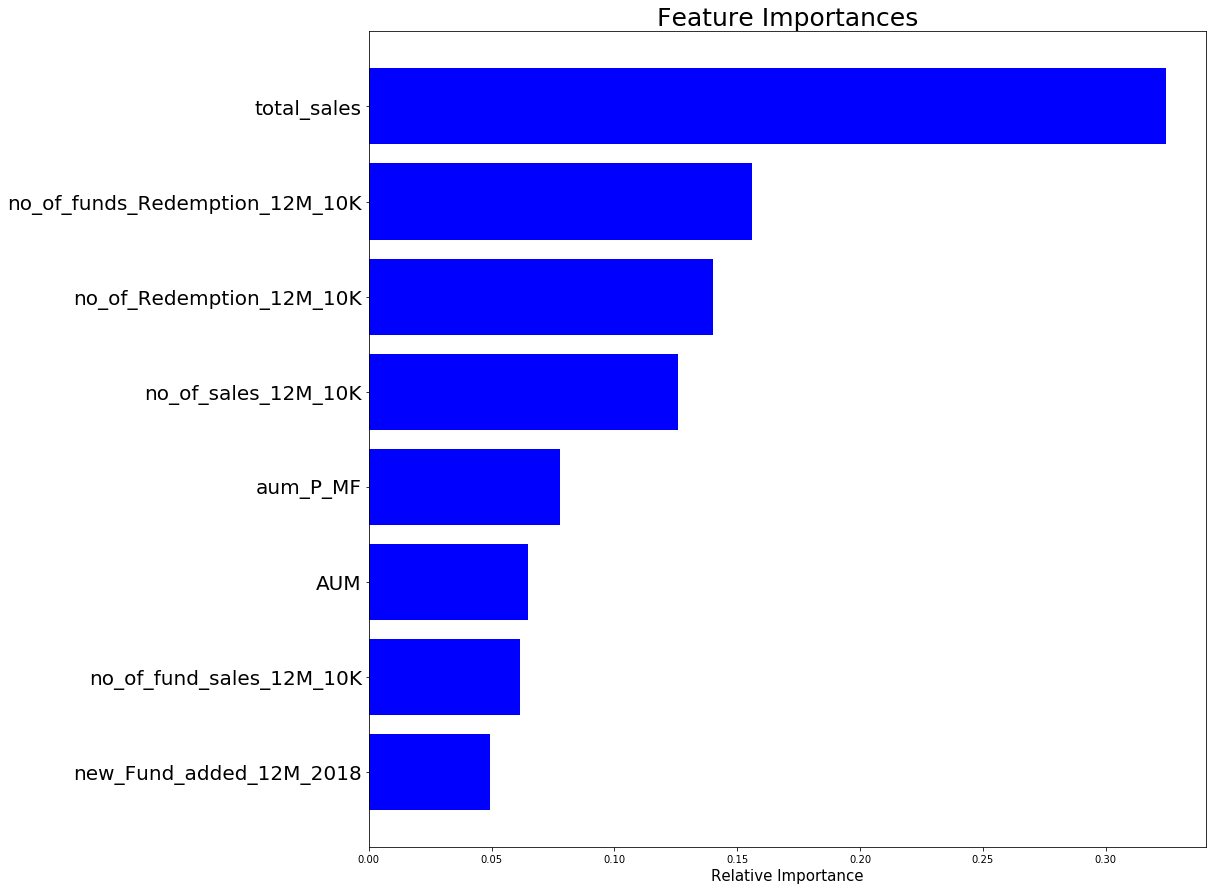

In [85]:
features = X_train_prepared.columns
importances = feat_pipe[0].feature_importances_
indices = np.argsort(importances)
plt.figure(figsize=(15,15), )
plt.title('Feature Importances', size=25)
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices],size=20 ), 
plt.xlabel('Relative Importance', size = 15)
plt.show()
#plt.savefig('feat_imp_1112_f2_7feat.png', dpi=100, bbox_inches='tight')

In [86]:
#X_test_prepared
X_train_prepared

#### [back to top](#Index)

## Cross validation

In [87]:
-cross_validate(feat_pipe, X_train_prepared, y_train_reg , scoring='neg_root_mean_squared_error')['test_score']

array([ 555333.9477817 , 1075544.92028133,  839875.43475371,
       1155440.3258306 ,  965056.92123699])

In [88]:
def evaluate_model(model, X, y):
    print("Cross Validation Scores:")
    print(cross_validate(model, X, y, scoring='neg_root_mean_squared_error')['test_score'])
    print('-'*55)
    preds = model.predict(X)
    lim = max(preds.max(), y.max())
    fig, ax = plt.subplots(1,1,figsize=(7,5))
    ax.scatter(x=y, y=preds, alpha=0.4)
    ax.plot([0, 20000000], [0, 20000000])
    ax.set_xlim([0, 20000000])
    ax.set_ylim([0, 20000000])
    ax.set_title("Actual vs Predicted - Regression")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

Cross Validation Scores:
[ -555333.9477817  -1075544.92028133  -839875.43475371 -1155440.3258306
  -965056.92123699]
-------------------------------------------------------


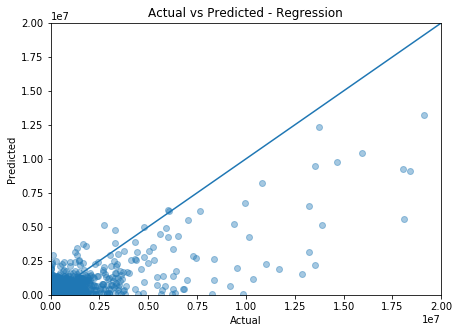

In [89]:
evaluate_model(feat_pipe, X_train_prepared, y_train_reg)

[Back to Top](#Index)
### Make Function to output deciles

In [90]:
def output_deciles(model, X, y):
    results = pd.DataFrame(model.predict(X), index=y.index, columns=['prediction'])
    results['actual'] = y.values
    results['deciles'] = pd.qcut(results['prediction'].rank(method='first'), 10, labels=False )
    results['contact_id'] = results.index.map(adviser_lookup)
    return results

In [91]:
result_df = output_deciles(feat_pipe, X_train_prepared, y_train_reg)
result_df

In [92]:
best_reg = result_df[result_df['deciles'] == 9]
best_reg.rename(columns={'contact_id': 'CONTACT_ID'},  inplace=True)
best_reg

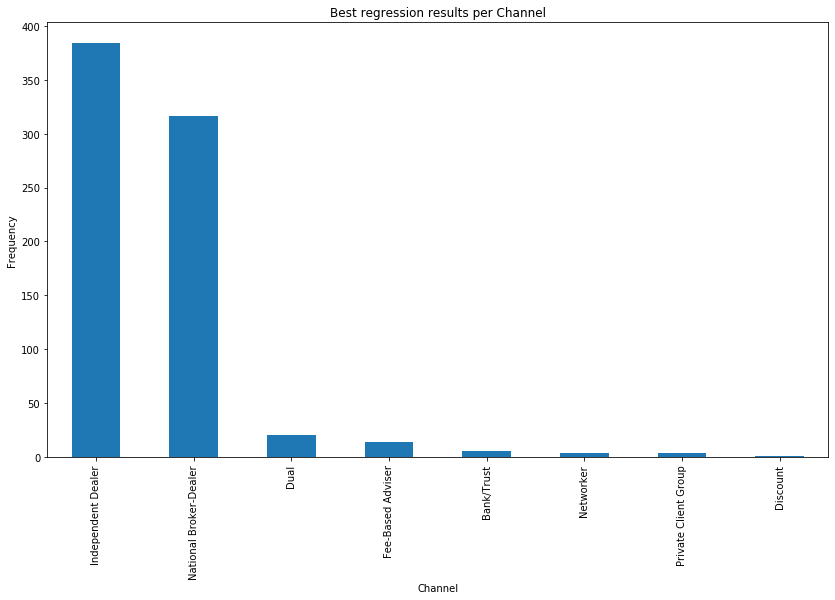

In [143]:
reg_full = pd.merge(full_df_class, best_reg, on='CONTACT_ID')
reg_full
ax = reg_full['Channel'].value_counts().plot(kind='bar',
                                    figsize=(14,8),
                                    title="Best regression results per Channel")
ax.set_xlabel("Channel")
ax.set_ylabel("Frequency")
plt.savefig('regression_channels.png',bbox_inches='tight')

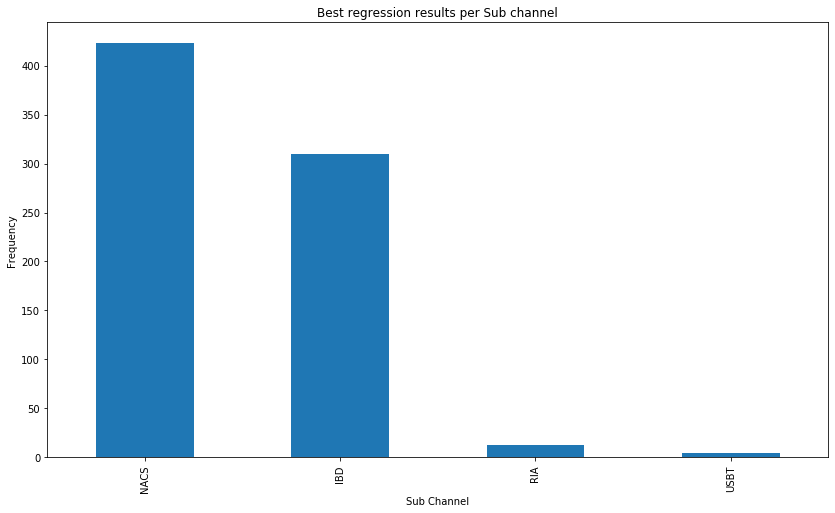

In [144]:
ax = reg_full['Sub channel'].value_counts().plot(kind='bar',
                                    figsize=(14,8),
                                    title="Best regression results per Sub channel")
ax.set_xlabel("Sub Channel")
ax.set_ylabel("Frequency")
plt.savefig('regression_sub_channels.png',bbox_inches='tight')

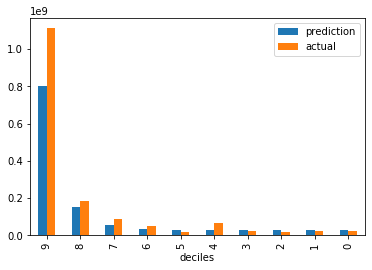

In [145]:
result_df.drop(columns='contact_id').groupby('deciles').sum().sort_index(ascending=False).plot(kind='bar');
plt.savefig('deciles.png')

#### [back to top](#Index)
# Some analysis

In [62]:
#plt.hist(X_test_prepared['no_of_Redemption_12M_10K'],bins=100)

# no_cols = [i for i in X_train_prepared.columns]
# df_cl_nz[no_cols].hist(figsize = (16,8), bins=100)
# plt.tight_layout()

#plt.hist(X_train_prepared['sales_12M_2018'], bins=200)

#### [back to top](#Index)
# Feature

In [63]:
#X_train_prepared.corr().style.background_gradient().set_precision(2)

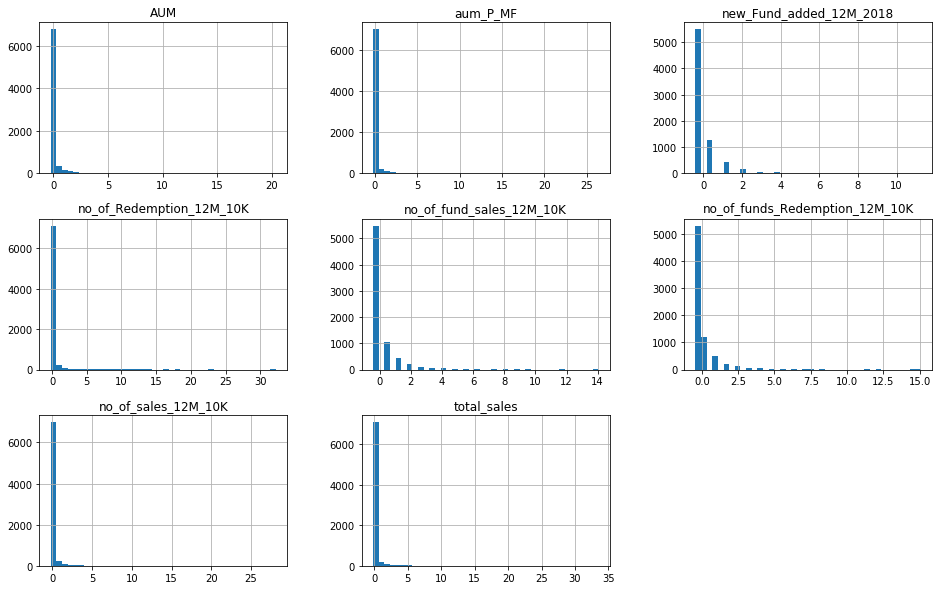

In [97]:
X_train_prepared.hist(bins=40, figsize=(16,10));

In [55]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer

class ReduceVIF(BaseEstimator, TransformerMixin):
    def __init__(self, thresh=10.0, impute=True, impute_strategy='median'):
        # From looking at documentation, values between 5 and 10 are "okay".
        # Above 10 is too high and so should be removed.
        self.thresh = thresh
        
        # The statsmodel function will fail with NaN values, as such we have to impute them.
        # By default we impute using the median value.
        # This imputation could be taken out and added as part of an sklearn Pipeline.
        if impute:
            self.imputer = SimpleImputer(strategy=impute_strategy)

    def fit(self, X, y=None):
        print('ReduceVIF fit')
        if hasattr(self, 'imputer'):
            self.imputer.fit(X)
        return self

    def transform(self, X, y=None):
        print('ReduceVIF transform')
        columns = X.columns.tolist()
        if hasattr(self, 'imputer'):
            X = pd.DataFrame(self.imputer.transform(X), columns=columns)
        return ReduceVIF.calculate_vif(X, self.thresh)

    @staticmethod
    def calculate_vif(X, thresh=5.0):
        # Taken from https://stats.stackexchange.com/a/253620/53565 and modified
        dropped=True
        while dropped:
            variables = X.columns
            dropped = False
            vif = [variance_inflation_factor(X[variables].values, X.columns.get_loc(var)) for var in X.columns]
            
            max_vif = max(vif)
            if max_vif > thresh:
                maxloc = vif.index(max_vif)
                print(f'Dropping {X.columns[maxloc]} with vif={max_vif}')
                X = X.drop([X.columns.tolist()[maxloc]], axis=1)
                dropped=True
        return X

In [56]:
funds = pd.concat([X_train_prepared, y_train_reg.to_frame()], axis=1)
features = funds.columns.tolist()
target = 'sales_12M_2019'

In [57]:
transformer = ReduceVIF()

X_tr_vif = transformer.fit_transform(X_train_prepared, y_train_reg)
X_tr_vif.head()

ReduceVIF fit
ReduceVIF transform


Dropping AUM with vif=inf
Dropping aum_AC_EQUITY with vif=inf
Dropping aum_AC_REAL_ESTATE with vif=92.7971150679493
Dropping no_of_funds_sold_12M_1 with vif=11.325901037576934


In [61]:
X_test_vif= transformer.transform(X_test_prepared, y_test_reg)

ReduceVIF transform
Dropping AUM with vif=inf


Dropping aum_AC_EQUITY with vif=inf
Dropping no_of_funds_sold_12M_1 with vif=12.737854466894921


In [62]:
feat_pipe.fit(X_tr_vif,y_train_reg)

Pipeline(steps=[('gradient',
                 GradientBoostingRegressor(learning_rate=0.02, max_depth=2))])

In [63]:
feat_pipe.score(X_tr_vif, y_train_reg)

0.4821980158949577

In [66]:
X_test_vif

In [71]:
#X_test_vif=X_test_vif.drop(['aum_AC_REAL_ESTATE'], axis=1)
feat_pipe.score(X_test_vif, y_test_reg)

0.5010896525676372

#### [back to top](#Index)

# Make predictions

In [355]:
#cross_validate(feat_pipe, X_train, y_train)

In [185]:
## use new X_train and test from RFECV
y_tr_rfe = feat_pipe.predict(X_train_prepared)
y_te_rfe = feat_pipe.predict(X_test_prepared)

In [756]:
# # with vif reduction
# y_tr_vif_preds = feat_pipe.predict(X_tr_vif)
# y_te_vif_preds = feat_pipe.predict(X_test_vif)

In [98]:
#  make regression predictions
y_train_preds = feat_pipe.predict(X_train_prepared)
y_test_preds = feat_pipe.predict(X_test_prepared)

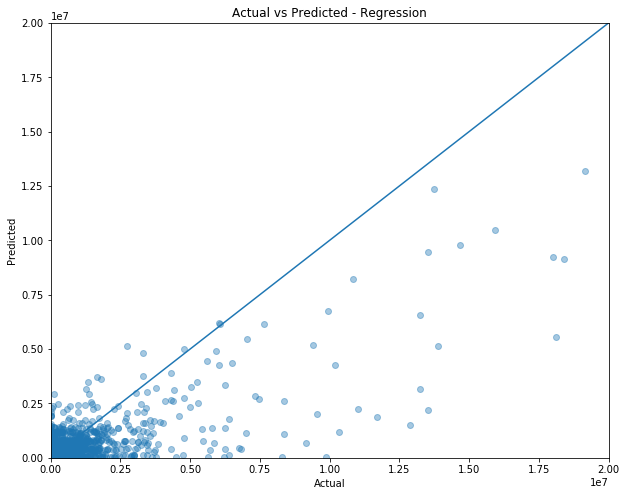

In [99]:
fig, ax = plt.subplots(1,1,figsize=(10,8))
ax.scatter(x=y_train_reg, y=y_train_preds, alpha=0.4)
ax.plot([0, 20000000], [0,20000000])
ax.set_xlim([0, 20000000])
ax.set_ylim([0, 20000000])
ax.set_title("Actual vs Predicted - Regression")
ax.set_xlabel("Actual")
ax.set_ylabel("Predicted");

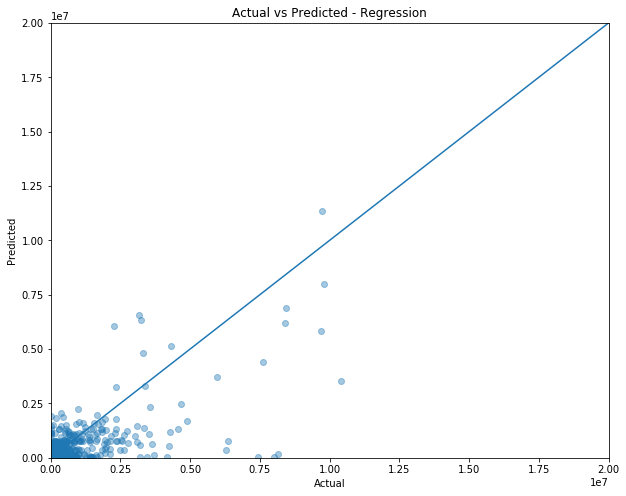

In [100]:
fig, ax = plt.subplots(1,1,figsize=(10,8))
ax.scatter(x=y_test_reg, y=y_test_preds, alpha=0.4)
ax.plot([0, 20000000], [0,20000000])
ax.set_xlim([0, 20000000])
ax.set_ylim([0, 20000000])
ax.set_title("Actual vs Predicted - Regression")
ax.set_xlabel("Actual")
ax.set_ylabel("Predicted");

In [101]:
## try r2 scores
metrics.r2_score(y_train_reg, y_train_preds)
#metrics.r2_score(y_test_reg, y_test_preds)

0.5111162257787103

#### [back to top](#Index)
## Classification

In [102]:
print(full_df.columns)

Index(['CONTACT_ID', 'no_of_sales_12M_1', 'no_of_Redemption_12M_1',
       'no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_funds_sold_12M_1', 'no_of_funds_redeemed_12M_1',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K',
       'no_of_assetclass_sold_12M_1', 'no_of_assetclass_redeemed_12M_1',
       'no_of_assetclass_sales_12M_10K', 'no_of_assetclass_Redemption_12M_10K',
       'No_of_fund_curr', 'No_of_asset_curr', 'AUM', 'sales_curr',
       'sales_12M_2018', 'redemption_curr', 'redemption_12M',
       'new_Fund_added_12M_2018', 'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'refresh_date_2018',
       'sales_12M_2019', 'new_Fund_added_12M_2019', 'refresh_date_2019',
       'total_sales'

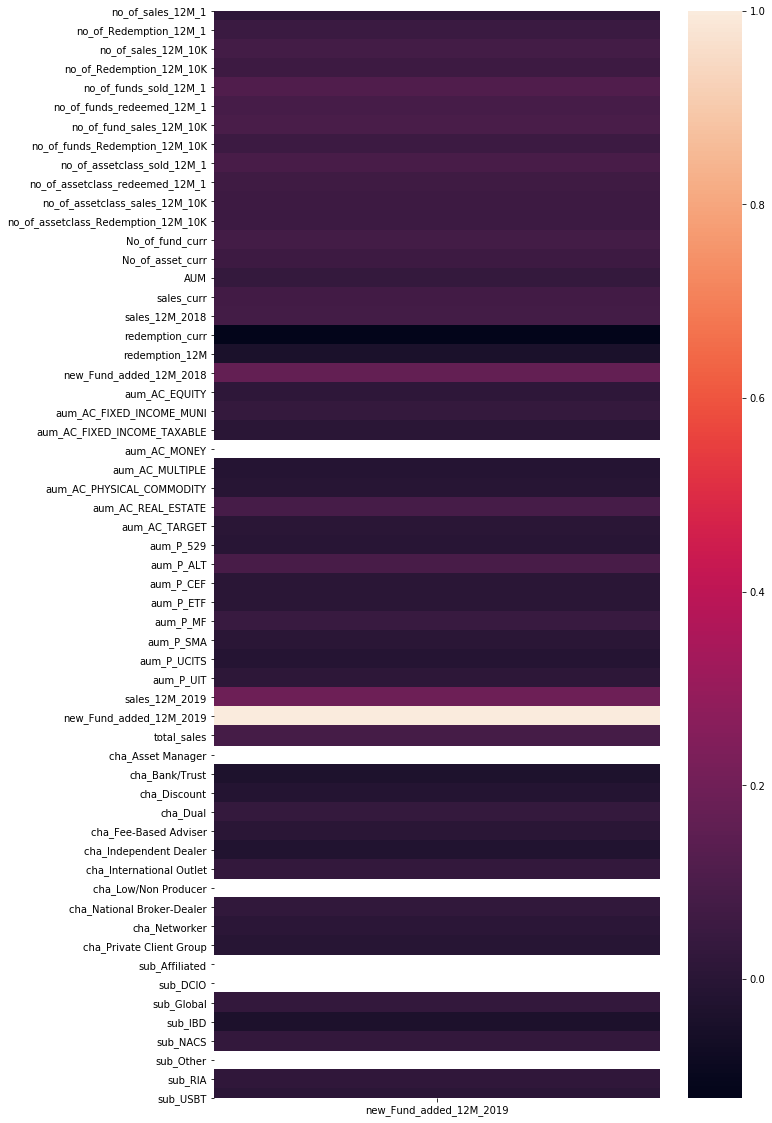

In [103]:
##heatmap with more data
corr = full_df.corr()
plt.figure(figsize=(10,20))
sns.heatmap(corr[['new_Fund_added_12M_2019']])

In [104]:
X_train_prepared

In [105]:
print(X_train_prepared.columns)

Index(['no_of_sales_12M_10K', 'no_of_Redemption_12M_10K',
       'no_of_fund_sales_12M_10K', 'no_of_funds_Redemption_12M_10K', 'AUM',
       'aum_P_MF', 'total_sales', 'new_Fund_added_12M_2018'],
      dtype='object')


In [111]:
#heat_map_cols=(['no_of_sales_12M_10K', 'no_of_funds_Redemption_12M_10K','total_sales'])

In [546]:
# ## Select from X_test and train (and prepared)
# X_train=X_train[heat_map_cols]
# X_test=X_test[heat_map_cols]
# X_train_prepared=X_train_prepared[heat_map_cols]
# X_test_prepared=X_test_prepared[heat_map_cols]

In [106]:
y_train_cl.value_counts()

0    5601
1    1899
Name: new_Fund_added_12M_2019, dtype: int64

In [107]:
y_test_cl.value_counts()

0    1882
1     619
Name: new_Fund_added_12M_2019, dtype: int64

In [108]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report
from xgboost import XGBClassifier

In [109]:
gbt_base = GradientBoostingClassifier()
gbt_base.fit(X_train_prepared, y_train_cl)
test_pred_class = gbt_base.predict(X_test_prepared)
#print(classification_report(y_test_cl, test_pred_class))
gbt_base.score(X_train_prepared, y_train_cl)

0.7765333333333333

In [110]:
gbt_base.score(X_test_prepared, y_test_cl)

0.7465013994402239

In [111]:
xbt_base = XGBClassifier(max_depth = 3, min_child_weight=3, eta= 0.3, subsample= 0.7,  colsample_bytree =1.0, learning_rate=0.05)
xbt_base.fit(X_train_prepared, y_train_cl)
test_pred_class = xbt_base.predict(X_test_prepared)
print(classification_report(y_test_cl, test_pred_class))
xbt_base.score(X_train_prepared, y_train_cl)

              precision    recall  f1-score   support

           0       0.76      0.97      0.85      1882
           1       0.47      0.07      0.12       619

    accuracy                           0.75      2501
   macro avg       0.61      0.52      0.49      2501
weighted avg       0.69      0.75      0.67      2501



0.7634666666666666

In [112]:
xbt_base.score(X_test_prepared, y_test_cl)

0.7500999600159935

In [113]:
xbt_base.feature_importances_

array([0.07430709, 0.06162943, 0.09420589, 0.08858912, 0.09738027,
       0.0727566 , 0.27187037, 0.23926125], dtype=float32)

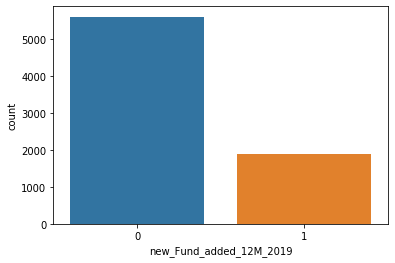

In [114]:
sns.countplot(y_train_cl)

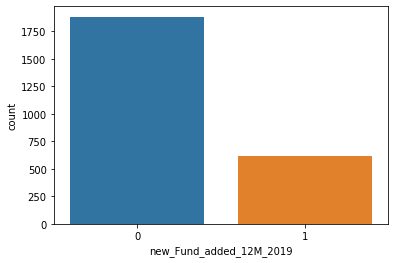

In [115]:
sns.countplot(y_test_cl)

In [116]:
y_train_baseline = 1- y_train_cl.sum()/len(y_train_cl)
y_train_baseline

0.7468

In [117]:
y_test_baseline = 1 - y_test_cl.sum()/len(y_test_cl)
y_test_baseline

0.7524990003998401

In [118]:
d = {'Stats':X_train_prepared.columns,'FI':xbt_base.feature_importances_}
df2 = pd.DataFrame(d)
#plot_feature_importances(forest)
df2

,Stats,FI
0,no_of_sales_12M_10K,0.074307
1,no_of_Redemption_12M_10K,0.061629
2,no_of_fund_sales_12M_10K,0.094206
3,no_of_funds_Redemption_12M_10K,0.088589
4,AUM,0.097380
5,aum_P_MF,0.072757
6,total_sales,0.271870
7,new_Fund_added_12M_2018,0.239261


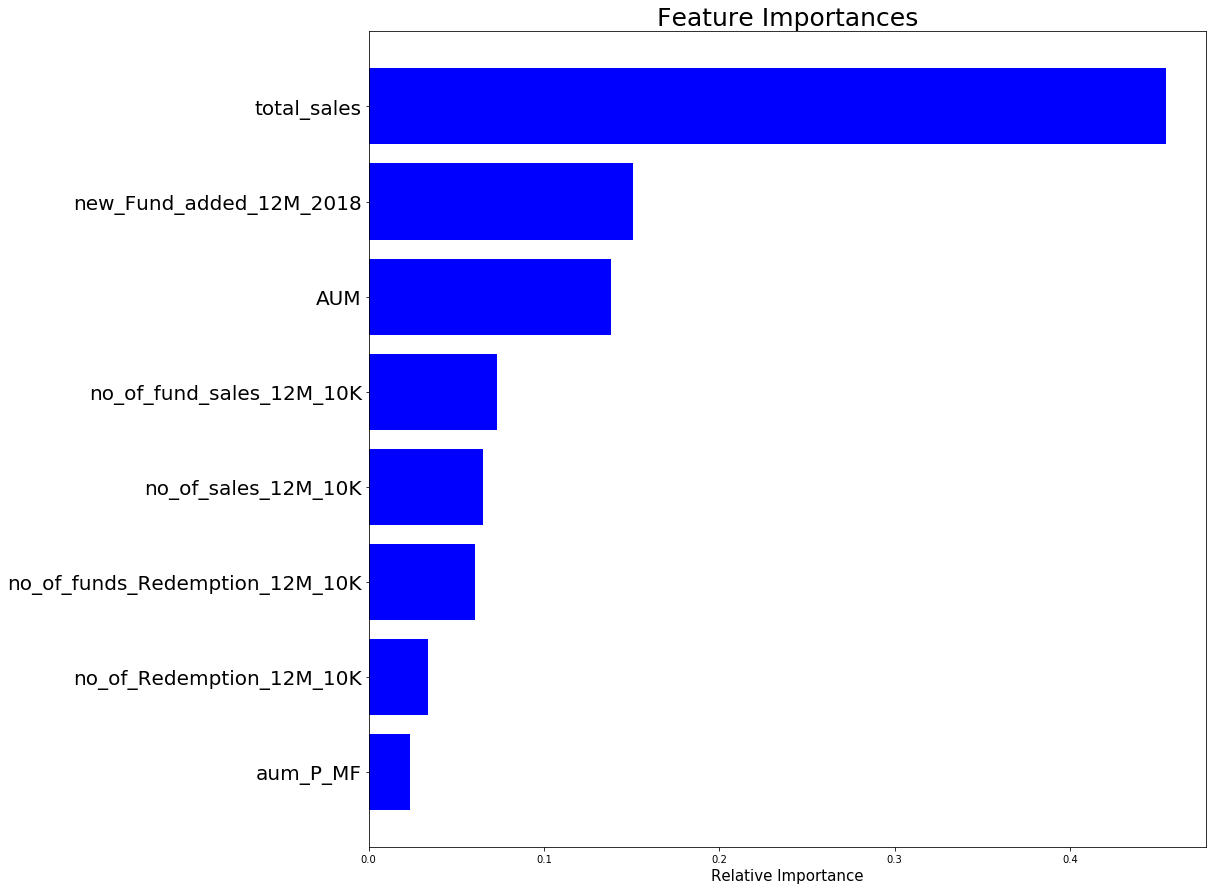

In [150]:
features = X_train_prepared.columns
importances = xbt_base.feature_importances_
indices = np.argsort(importances)
plt.figure(figsize=(15,15), )
plt.title('Feature Importances', size=25)
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices],size=20 ), 
plt.xlabel('Relative Importance', size = 15)
#plt.show()
plt.savefig("fet_imp_classification.png", bbox_inches='tight')

In [151]:
from imblearn.over_sampling import SMOTE

In [152]:
smote = SMOTE()

In [153]:
X_train_resample, y_train_cl_resample = smote.fit_resample(X_train_prepared, y_train_cl)

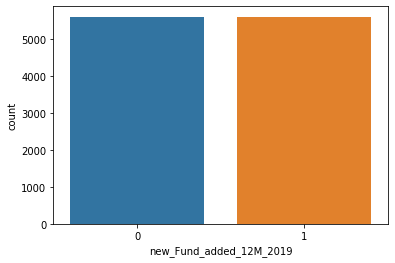

In [154]:
sns.countplot(y_train_cl_resample)
#plt.savefig('basline_train.png')

In [155]:
xbt_base = XGBClassifier(max_depth = 3, min_child_weight=1, eta= 0.3, subsample= 0.9,  colsample_bytree =1.0, learning_rate=0.01)
xbt_base.fit(X_train_resample, y_train_cl_resample)
#test_pred_class = xbt_base.predict(X_test_prepared)
#print(classification_report(y_test_cl, test_pred_class))
xbt_base.score(X_train_resample, y_train_cl_resample)

0.6375647205856098

In [156]:
xbt_base.score(X_test_prepared, y_test_cl)

0.6217512994802079

In [157]:
X_test_resample, y_test_cl_resample = smote.fit_resample(X_test_prepared, y_test_cl)

In [158]:
xbt_base.score(X_test_resample, y_test_cl_resample)

0.6256641870350691

In [118]:
#pip install scikit-plot

In [159]:
import scikitplot as skplot

In [160]:
probs = xbt_base.predict_proba(X_test_resample)

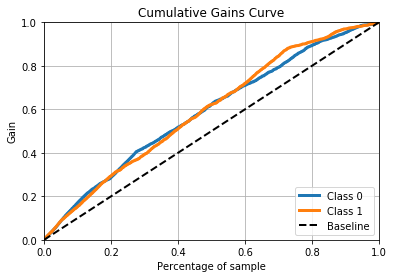

In [162]:
skplot.metrics.plot_cumulative_gain(y_test_cl_resample, probs)
#plt.savefig('gain_classification.png')

In [192]:
def clac_lift (X, y, clf, n=10):
    y_true=y
    prob = clf.predict_proba(X)[:,1]
    y_preds = clf.predict(X)
    
    df= pd.DataFrame({'true':y_true, 'prob':prob,'predict':y_preds})
    true_1s = df['true'].sum()
    total_obs = df.shape[0]
    pos_prob= true_1s/total_obs
    df['decile'] = pd.qcut(df['prob'],n, duplicates='drop')
    pos_df = df.groupby('decile')
    tamanho = pos_df.size()
    
    lift_pos = pos_df['true'].sum()/pos_df['true'].count()
    lift_ind_positive = lift_pos*100
    
    lift_df = pd.DataFrame({'Lift positve':lift_ind_positive,
                           'baseline': pos_prob, 'size': tamanho})
    return lift_df

In [195]:
df_class = clac_lift(X_train_resample, y_train_cl_resample, xbt_base)
df_class.to_csv(path_or_buf='classification_deciles',index=False,sep='-')
df_class
#df_class.to_csv(path_or_buf='classification_deciles_table',index=False)

,Lift positve,baseline,size
decile,,,
"(0.322, 0.345]",21.027668,0.5,1265
"(0.345, 0.453]",42.259857,0.5,3779
"(0.453, 0.491]",36.274510,0.5,612
"(0.491, 0.537]",51.858254,0.5,1157
"(0.537, 0.55]",53.741497,0.5,1029
"(0.55, 0.566]",61.762115,0.5,1135
"(0.566, 0.642]",67.058824,0.5,1105
"(0.642, 0.707]",82.232143,0.5,1120


In [187]:
y_true=y_train_cl_resample
prob = xbt_base.predict_proba(X_train_resample)[:,1]
y_preds = xbt_base.predict(X_train_resample)
    
df_class= pd.DataFrame({'true':y_true, 'prob':prob,'predict':y_preds})
true_1s = df['true'].sum()
total_obs = df.shape[0]
pos_prob= true_1s/total_obs
#df['decile'] = pd.qcut(df['prob'],10, duplicates='drop')
#pos_df = df.groupby('decile')
    
# lift_pos = pos_df['true'].sum()/pos_df['true'].count()
# lift_ind_positive = lift_pos/pos_prob*100
    
# lift_df = pd.DataFrame({'lift_positive':lift_pos,'lift_pos_index':lift_ind_positive,
#                            'baseline': pos_prob})
df_class_top = df_class[df_class['prob']>0.64]
df_class_top
df_class_top['contact_id'] = df_class_top.index.map(adviser_lookup)
#results['contact_id'] = results.index.map(adviser_lookup)
df_class_top

KeyError: 'true'

In [134]:
firms.rename(columns={'Contact ID': 'CONTACT_ID'},  inplace=True)
df_class_top.rename(columns={'contact_id':'CONTACT_ID'}, inplace=True)

NameError: name 'df_class_top' is not defined

In [135]:

class_full = pd.merge(full_df_class, df_class_top, on='CONTACT_ID')
class_full
ax = class_full['Channel'].value_counts().plot(kind='bar',
                                    figsize=(14,8),
                                    title="Best classification results per Channel")
ax.set_xlabel("Channel")
ax.set_ylabel("Frequency")
plt.savefig('class_channels.png',bbox_inches='tight')

NameError: name 'full_df_class' is not defined

In [136]:
full_df_class['Sub channel'].value_counts()

NameError: name 'full_df_class' is not defined

In [137]:
ax = class_full['Sub channel'].value_counts().plot(kind='bar',
                                    figsize=(14,8),
                                    title="Best classification results per Sub channel")
ax.set_xlabel("Sub channel")
ax.set_ylabel("Frequency")
plt.savefig('class_sub_channels.png',bbox_inches='tight')

NameError: name 'class_full' is not defined

In [138]:
result_df_cl = output_deciles(xbt_base, X_train_resample, y_train_cl_resample)
result_df_cl

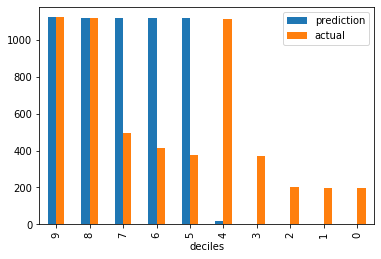

In [139]:
result_df_cl.drop(columns='contact_id').groupby('deciles').sum().sort_index(ascending=False).plot(kind='bar');

#### [back to top](#Index)

# Other way 
this was done follwoing Monday notes

In [ ]:
    ## Some graphs
len(firms['Firm name'].unique())
full_df.groupby('Firm name')[['total_sales']].mean().nlargest(10,'total_sales').plot(kind='barh')

#plt.scatter(full_df['total_sales'], full_df['sales_12M_2019'], alpha=0.3, edgecolor='black')
#plt.xlabel('Total Sales year prior')
#plt.ylabel('Total Sales next Year')

In [76]:
plt.scatter(full_df['total_sales'], full_df['sales_12M_2019'], alpha=0.3, edgecolor='black')
plt.xlabel('Total Sales year prior')
plt.ylabel('Total Sales next Year')

KeyError: 'total_sales'

count    1.000500e+04
mean     3.405775e+05
std      3.246426e+06
min     -7.713610e+07
25%     -2.927447e+04
50%      2.391812e+01
75%      1.484115e+05
max      2.232411e+08
Name: AUM, dtype: float64

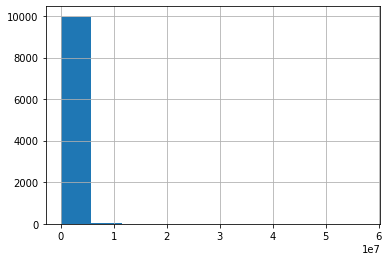

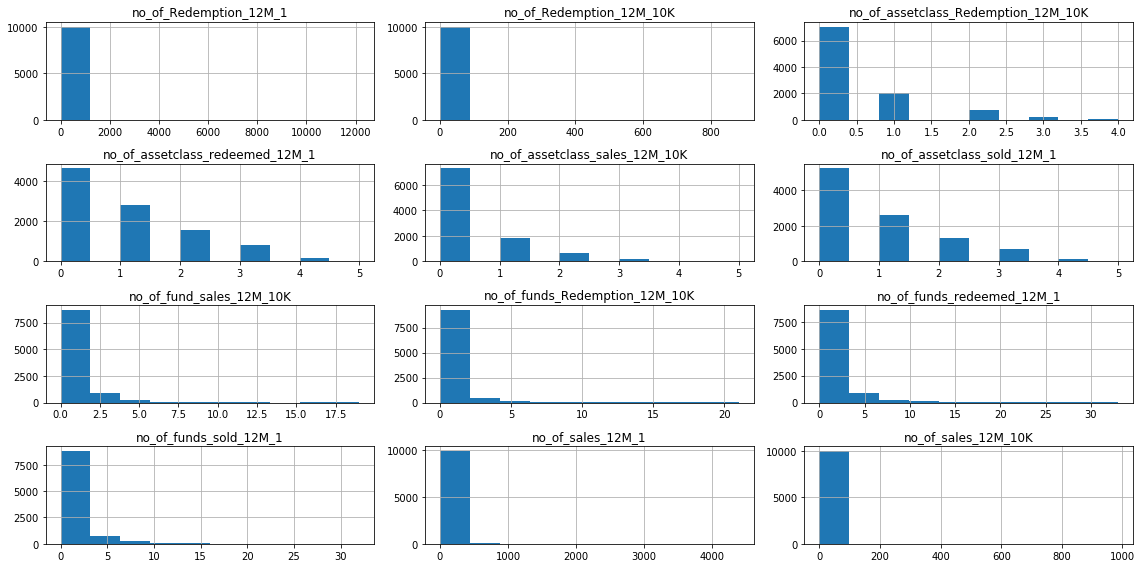

In [54]:
   ## Check Histograms of columns
df_cl_nz['total_sales'].hist()
#plt.scatter(df_cl_nz['total_sales'], y)
plt.hist(df_cl_nz['no_of_sales_12M_1'], bins  =100)
plt.hist(df_cl_nz['no_of_Redemption_12M_1'], bins=100)

no_cols = [i for i in df_cl_nz.columns if i.startswith('no')]
df_cl_nz[no_cols].hist(figsize = (16,8))
plt.tight_layout()

df_cl_nz['AUM'].describe()

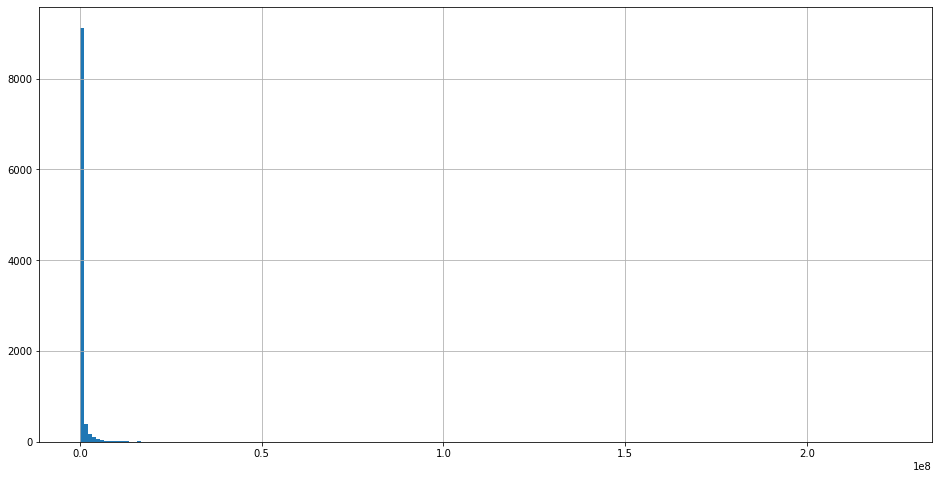

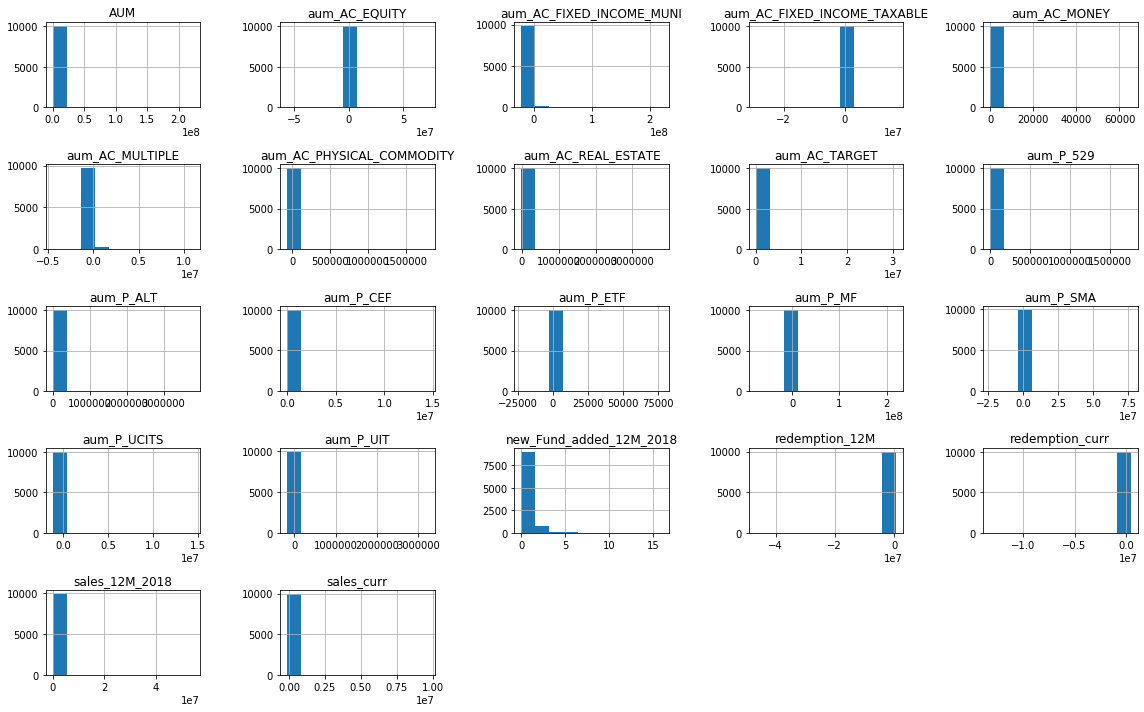

In [55]:
 ## Make negative values under 'AUM' to zeros
def zero_filler(x):
    if x <0:
        return 0
    else:
        return x
    
df_cl_nz['AUM'] = df_cl_nz['AUM'].apply(zero_filler)
df_cl_nz['AUM'].hist(figsize = (16,8), bins= 200)

df_cl_nz[['AUM', 'sales_curr', 'sales_12M_2018',
       'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
       'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT']].hist(figsize = (16,10))
plt.tight_layout()

aum_cols = [i for i in df_cl_nz.columns if i.startswith('aum')]
for col in aum_cols:
    df_cl_nz[col] = df_cl_nz[col].apply(zero_filler)




In [56]:
df_cl_nz['AUM'].describe()

count    1.000500e+04
mean     4.850002e+05
std      2.993438e+06
min      0.000000e+00
25%      0.000000e+00
50%      2.391812e+01
75%      1.484115e+05
max      2.232411e+08
Name: AUM, dtype: float64

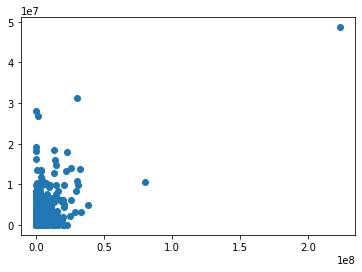

In [57]:
## checking AUM as predictor
plt.scatter(df_cl_nz['AUM'], df_cl_nz['sales_12M_2019'])

In [58]:
## test some transformations
print(df_cl_nz.columns)
X = df_cl_nz[['AUM', 'sales_12M_2018']]
y = df_cl_nz[['sales_12M_2019']]

transformer = QuantileTransformer(output_distribution='normal')
regressor = LinearRegression()
regr = TransformedTargetRegressor(regressor=regressor, transformer=transformer)
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=0)
regr.fit (X_train, y_train)

Index(['no_of_sales_12M_1', 'no_of_Redemption_12M_1', 'no_of_sales_12M_10K',
       'no_of_Redemption_12M_10K', 'no_of_funds_sold_12M_1',
       'no_of_funds_redeemed_12M_1', 'no_of_fund_sales_12M_10K',
       'no_of_funds_Redemption_12M_10K', 'no_of_assetclass_sold_12M_1',
       'no_of_assetclass_redeemed_12M_1', 'no_of_assetclass_sales_12M_10K',
       'no_of_assetclass_Redemption_12M_10K', 'No_of_fund_curr',
       'No_of_asset_curr', 'AUM', 'sales_curr', 'sales_12M_2018',
       'redemption_curr', 'redemption_12M', 'new_Fund_added_12M_2018',
       'aum_AC_EQUITY', 'aum_AC_FIXED_INCOME_MUNI',
       'aum_AC_FIXED_INCOME_TAXABLE', 'aum_AC_MONEY', 'aum_AC_MULTIPLE',
       'aum_AC_PHYSICAL_COMMODITY', 'aum_AC_REAL_ESTATE', 'aum_AC_TARGET',
       'aum_P_529', 'aum_P_ALT', 'aum_P_CEF', 'aum_P_ETF', 'aum_P_MF',
       'aum_P_SMA', 'aum_P_UCITS', 'aum_P_UIT', 'total_sales',
       'sales_12M_2019', 'new_Fund_added_12M_2019'],
      dtype='object')


TransformedTargetRegressor(regressor=LinearRegression(),
                           transformer=QuantileTransformer(output_distribution='normal'))

In [59]:
regr.score (X_train,y_train)

-0.68048451989442

In [60]:
regr.score(X_test,y_test)

-1.0555547227827882

In [61]:
## subsetting for heatmap
cols = ['no_of_sales_12M_1','no_of_Redemption_12M_1', 'AUM','total_sales',
       'No_of_fund_curr','No_of_asset_curr','sales_12M_2019']
sub_df = df_cl_nz.loc[:,cols]
sub_df.head()

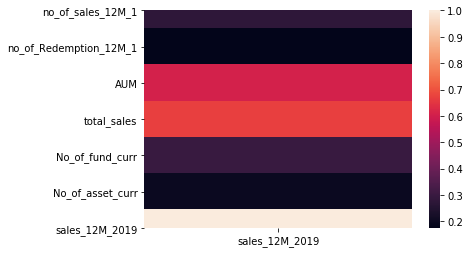

In [62]:
##heatmap
corr = sub_df.corr()
sns.heatmap(corr[['sales_12M_2019']])
    

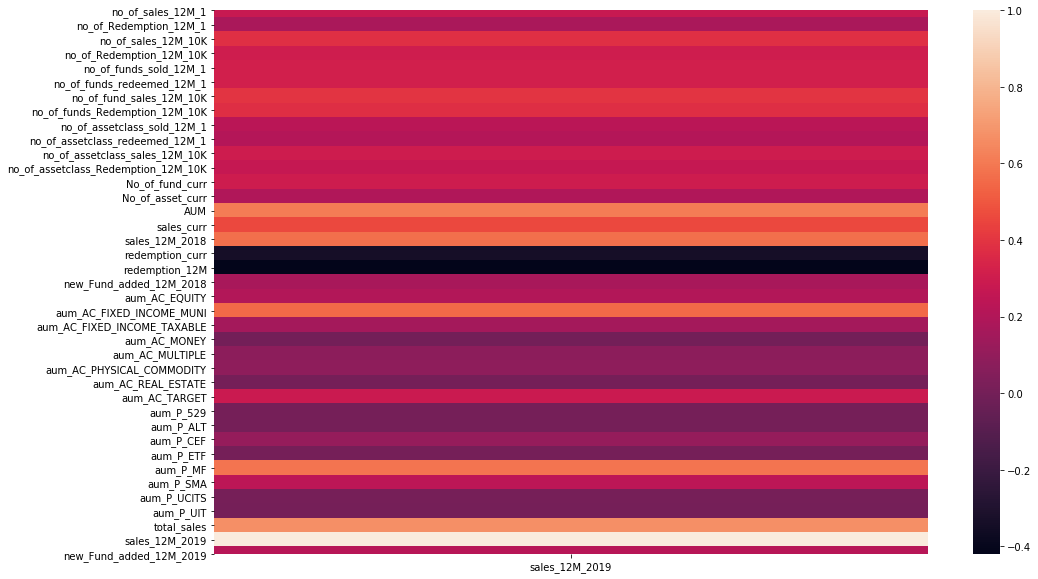

In [63]:
##heatmap with more data
corr = df_cl_nz.corr()
plt.figure(figsize=(16,10))
sns.heatmap(corr[['sales_12M_2019']])

In [64]:
#X = sub_df.drop(['sales_12M_2019','no_of_Redemption_12M_1','No_of_asset_curr'], axis=1)
#y = sub_df['sales_12M_2019']
##Select columns for dataset after analyzing heatmap:
cols = ['no_of_fund_sales_12M_10K','no_of_sales_12M_10K', 'AUM', 'sales_curr', 'sales_12M_2018','aum_AC_FIXED_INCOME_MUNI',
       'aum_P_MF','total_sales']
X = df_cl_nz.loc[:,cols]
y = df_cl_nz['sales_12M_2019']

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X,y)
dtree = DecisionTreeRegressor()
trans = StandardScaler()
trans.fit_transform(X_train)
dtree.fit(X_train, y_train)
dtree.score(X_train, y_train)




0.9923459360041436

In [66]:
#trans.fit_transform(X_test)
dtree.score(X_test,y_test)

-1.6317697236352093

In [67]:
#print(sub_df.columns)

In [68]:
##GridSearch
params={'max_depth': [3,4,5,6]}
grid = GridSearchCV(dtree, param_grid=params)
grid.fit(X_train, y_train)

GridSearchCV(estimator=DecisionTreeRegressor(),
             param_grid={'max_depth': [3, 4, 5, 6]})

In [69]:
grid.score(X_train,y_train)

0.781919462455192

In [70]:
grid.score(X_test, y_test)

-0.006936825189782114

In [71]:
## try different models
gboost = GradientBoostingRegressor()
ada = AdaBoostRegressor()
forest = RandomForestRegressor()

In [72]:
trans.fit_transform(X_train)

gboost.fit(X_train, y_train)
gboost.score(X_train,y_train)

0.8440211200407093

In [73]:
gboost.score(X_test, y_test)

0.14562708914006162

In [74]:
trans.fit_transform(X_train)
ada.fit(X_train, y_train)
ada.score(X_train, y_train)

0.49936133682237194

In [75]:
ada.score(X_test, y_test)

-0.14409120845807033

In [76]:
forest.fit (X_train, y_train)
forest.score(X_train, y_train)

0.9112821146865523

In [77]:
forest.score(X_test, y_test)

0.14087880279447662

In [78]:
neigh = KNeighborsRegressor(n_neighbors=6)
neigh.fit(X_train, y_train)
neigh.score(X_train, y_train)

0.5450673607062999

In [79]:
neigh.score(X_test, y_test)

0.15783648106066683

In [80]:
svr = SVC()
svr.fit (X_train, y_train)
svr.score (X_train, y_train)

ValueError: Unknown label type: 'continuous'

In [ ]:
svr.score(X_test, y_test)

In [ ]:
print(X_train.head(5))